# D03 — Real-Damage Dataset Preparation

**Origin:** New Notebook — approved supplemental real-damage study  
**Dataset scope:** `real_damage_10`  
**Source cohort version:** `2.0.0`  
**Refactor status:** Finished                                   
**Validation status:** Finished                        
**Completion gate passed:** Yes                                       
**Output root:** `outputs/d03_real_damage_dataset_preparation/`

## Purpose

Prepare ten photographs of physically damaged paintings for digital restoration
using the same four methods as the controlled study: OpenCV Telea, LaMa, HINT
and Stable Diffusion.

D03 verifies the sources, applies the existing preprocessing policy, validates
selected repair masks and prepares the input records for D04. It does not run
restoration models.

## Approved revised population

The researcher approved the revised ten sources on 2026-11-15, with two paintings
in each existing operational visual category:

- portrait and figure;
- landscape and natural scenes;
- architecture and structured scenes;
- abstraction and surrealism;
- high texture and brushwork.

The revised sources use IDs `rd001`–`rd010`. Only the original `rd007` source,
Black Square, is retained from cohort v1.0.0. Other reused IDs refer to different
paintings, so records must retain their dataset version and source hash.

Earlier notebook outputs belong to the superseded cohort. Its sources,
unfinished outputs and notebook snapshot are preserved in ignored local recovery
storage. Their validation results do not validate this revised cohort.

The target remains ten reviewed cases and forty case–model eligibility records.

## Preprocessing and repair scope

The existing preprocessing remains unchanged: a 768 × 768 RGB canvas,
aspect-ratio preservation, Lanczos resizing, median-colour padding, the existing
ICC colour policy and recorded content bounds. No cropping is introduced.

The original source files remain unchanged. One source is a PNG with fully
opaque alpha; D03 drops that channel in memory without changing its RGB values,
then applies the same canonical preprocessing.

Existing physical damage replaces artificial damage generation. Selected binary
repair masks identify pixels to reconstruct: 0 means preserve and 255 means
reconstruct. These acquisition annotations are bound to the source and processed
image hashes. They are not exhaustive condition maps.

The researcher accepted partial repair scope: additional deterioration outside
a selected mask remains outside that restoration target. Ancient painted panels
may contain historical neutral fills or earlier treatment.

For Antigone (`rd002`), the mask includes additional flaking on the soldier and
background cliff. Its selected coverage is approximately 3.50% of image content.
The researcher permits this mask to exceed 15% if accurate tracing requires it;
no mask is enlarged merely to reach a percentage.

## Provenance and review

Source metadata records public-domain statements, Met CC0 provenance, and
CC BY 2.0 or CC BY-SA 4.0 photographic licences where applicable. Attribution,
licence links and adaptation conditions remain attached to the sources.

The selected masks have been visually reviewed during source selection. They
still require notebook validation, final hash binding and examination at Stable
Diffusion's existing 512-pixel inference resolution. Disappearing fine components
are recorded rather than silently enlarged.

## Interpretation boundaries

No known clean reference exists for these photographs. The damaged input must
not become a substitute clean reference.

Interior MAE, PSNR, SSIM or reference-based LPIPS therefore cannot establish
restoration accuracy for this collection. Synthetic-case reference measurements
remain separate evidence.

Category labels describe this purposive selection, including ancient wall
paintings, fantastical imagery and texture-focused figurative works. Two
paintings per category support illustrative cases, not population-level rankings.

This supplement leaves the completed Controlled-300 experiments and dashboard
unchanged.

## Batch plan

1. Contract, environment and inventory preflight.
2. Source-image and provenance validation.
3. Representative preprocessing smoke test.
4. Full preprocessing and annotation preparation.
5. Human mask review and validation.
6. Mask geometry and model-eligibility audit.
7. Persistence, standalone report and manifests.
8. Completion gate and downstream handoff.

No manual mask drawing is required for the prepared selection. Review and
validation remain necessary before restoration.

## Canonical outputs

All paths below are relative to the D03 output root.

- `data/artworks.csv`
- `data/preprocessed_images.csv`
- `data/masks.csv`
- `data/mask_review.csv`
- `data/case_registry.csv`
- `data/model_eligibility.csv`
- `images/inputs/{painting_id}.png`
- `images/masks/{mask_id}.png`
- `metrics/mask_geometry.csv`
- `metrics/inference_mask_audit.csv`
- `figures/source_overview.png`
- `figures/mask_review_atlas.png`
- `reports/real_damage_dataset.html`
- `manifests/run_manifest.json`
- `manifests/artifacts.csv`
- `validation/checks.csv`

Temporary smoke and annotation-review artifacts belong under `work/`.
They are not final downstream inputs.

## Batch 1 — Revised-cohort preflight

Load cohort v2.0.0 and verify the approved population, declared inputs,
source and annotation hashes, current inventory and unchanged shared
preprocessing/model files.

The setup reloads the two D03 helpers and resets notebook readiness flags.
Earlier in-memory validation results are not carried into this revised run.

This batch does not create processed images or run restoration.

In [1]:
from pathlib import Path
from time import perf_counter
import importlib
import sys

import pandas as pd
from IPython.display import display, Image as NotebookImage

# Reset readiness for this revised-cohort run.
for batch_number in range(1, 9):
    globals()[f"BATCH_{batch_number}_READY"] = False

START_DIRECTORY = Path.cwd().resolve()
PROJECT_ROOT = next(
    (
        candidate
        for candidate in (START_DIRECTORY, *START_DIRECTORY.parents)
        if (candidate / ".git").exists()
        and (candidate / "src" / "restoration_eval").is_dir()
        and (candidate / "notebooks").is_dir()
    ),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        f"Could not locate the repository from {START_DIRECTORY}"
    )

SRC_ROOT = PROJECT_ROOT / "src"
if str(SRC_ROOT) not in sys.path:
    sys.path.insert(0, str(SRC_ROOT))

from restoration_eval import (
    manifests, masks, paths, preprocessing,
    regions, schemas, validation,
    real_damage_dataset, real_damage_preparation,
)

# Reload dependencies first; no kernel restart is required.
real_damage_dataset = importlib.reload(real_damage_dataset)
real_damage_preparation = importlib.reload(real_damage_preparation)
rd = real_damage_dataset

CONFIG_PATH = PROJECT_ROOT / "config/datasets/real_damage_10.yaml"
CONFIG = rd.load_real_damage_config(CONFIG_PATH)
SOURCE_CATALOG = rd.load_approved_sources(
    PROJECT_ROOT / CONFIG["inputs"]["approved_sources"], CONFIG
)

if CONFIG["dataset"]["dataset_version"] != "2.0.0":
    raise RuntimeError("Expected the approved revised cohort v2.0.0.")

NOTEBOOK_ID = CONFIG["notebook"]["id"]
NOTEBOOK_STEM = CONFIG["notebook"]["stem"]
NOTEBOOK_OUTPUT_ROOT = paths.notebook_output_root(
    NOTEBOOK_STEM, PROJECT_ROOT
)
INPUTS, OUTPUTS = rd.resolve_real_damage_paths(
    PROJECT_ROOT, CONFIG, SOURCE_CATALOG, config_path=CONFIG_PATH
)

RUN_STARTED_AT_UTC = manifests.utc_now_iso()
VALIDATION = validation.ValidationCollector()
ENVIRONMENT = manifests.environment_summary(
    package_names=[
        "numpy", "pandas", "Pillow", "PyYAML", "scipy", "matplotlib"
    ]
)
GIT_STATE = manifests.git_state(PROJECT_ROOT)

HELPER_VERSIONS = {
    "real_damage_dataset": rd.REAL_DAMAGE_DATASET_MODULE_VERSION,
    "real_damage_preparation":
        real_damage_preparation.REAL_DAMAGE_PREPARATION_MODULE_VERSION,
    "paths": paths.PATHS_MODULE_VERSION,
    "schemas": schemas.SCHEMAS_MODULE_VERSION,
    "manifests": manifests.MANIFESTS_MODULE_VERSION,
    "validation": validation.VALIDATION_MODULE_VERSION,
    "preprocessing": preprocessing.PREPROCESSING_MODULE_VERSION,
    "masks": masks.MASKS_MODULE_VERSION,
    "regions": regions.REGIONS_MODULE_VERSION,
}

EXPECTED_COUNTS = {
    "approved_source_images": 10,
    "paintings_per_category": 2,
    "preprocessed_images": 10,
    "reviewed_masks": 10,
    "case_rows": 10,
    "model_eligibility_rows": 40,
}

def show_validation_stage(stage):
    """Display the current stage and stop on unresolved validation failures."""
    checks = VALIDATION.to_dataframe()
    checks = checks.loc[checks["validation_stage"].eq(stage)].copy()
    if checks.empty:
        raise RuntimeError(f"No validation checks were recorded for {stage}.")

    display(pd.DataFrame([{
        "stage": stage,
        "checks": len(checks),
        "passed": int(checks["passed"].sum()),
        "failed": int((~checks["passed"]).sum()),
    }]))

    failed = checks.loc[~checks["passed"]]
    if not failed.empty:
        display(failed[
            ["check_id", "check_description", "expected",
             "observed", "details"]
        ])

    VALIDATION.raise_for_blocking()
    if not VALIDATION.overall_passed:
        raise RuntimeError("Resolve validation failures before continuing.")
    return checks

print("Notebook:", NOTEBOOK_ID, "-", NOTEBOOK_STEM)
print("Repository:", PROJECT_ROOT)
print("Dataset:", CONFIG["dataset"]["dataset_scope"])
print("Cohort version:", CONFIG["dataset"]["dataset_version"])
print("Python:", ENVIRONMENT["python_version"])
print("Declared inputs:", len(INPUTS))
print("Declared output paths:", len(OUTPUTS))
print("Output root:", NOTEBOOK_OUTPUT_ROOT)
print("Fresh validation state; no notebook outputs created.")

Notebook: D03 - d03_real_damage_dataset_preparation
Repository: D:\Masters\FH\Thesis\painting-restoration-eval
Dataset: real_damage_10
Cohort version: 2.0.0
Python: 3.12.6
Declared inputs: 60
Declared output paths: 17
Output root: D:\Masters\FH\Thesis\painting-restoration-eval\outputs\d03_real_damage_dataset_preparation
Fresh validation state; no notebook outputs created.


In [2]:
BATCH_1_READY = False

PREFLIGHT_RESULT = rd.validate_real_damage_preflight(
    PROJECT_ROOT,
    CONFIG,
    SOURCE_CATALOG,
    INPUTS,
    OUTPUTS,
    previous_validation=None,
)

VALIDATION = PREFLIGHT_RESULT["validation"]
INVENTORY_RUN = PREFLIGHT_RESULT["inventory"]
INPUT_AUDIT = PREFLIGHT_RESULT["input_audit"]
INPUT_CHECKSUMS = PREFLIGHT_RESULT["input_checksums"]

BATCH_1_CHECKS = show_validation_stage(rd.PREFLIGHT_STAGE)
BATCH_1_READY = True

print("Inventory run:", INVENTORY_RUN["inventory_run_id"])
print("Verified input checksums:", len(INPUT_CHECKSUMS))
print("Shared preprocessing and model baseline hashes passed.")
print("Batch 1 preflight passed.")

,stage,checks,passed,failed
0,batch_1_preflight,43,43,0


Inventory run: inventory_20261114T233431Z_0d63d625
Verified input checksums: 60
Shared preprocessing and model baseline hashes passed.
Batch 1 preflight passed.


In [3]:
if not BATCH_1_READY:
    raise RuntimeError("Pass Batch 1 preflight first.")

SOURCE_SELECTION = pd.DataFrame(SOURCE_CATALOG["records"])

with pd.option_context("display.max_colwidth", 90):
    display(SOURCE_SELECTION[
        [
            "painting_id",
            "title",
            "category",
            "license",
            "selected_mask_content_percent",
            "has_clean_reference",
        ]
    ])

display(
    SOURCE_SELECTION.groupby("category", sort=False)
    .size()
    .rename("paintings")
    .reset_index()
)

display(pd.DataFrame(
    EXPECTED_COUNTS.items(), columns=["expected_artifact", "count"]
))

print("Mask percentages describe selected repair targets, not all damage.")
print("Final mask validation and inference-scale review remain pending.")

,painting_id,title,category,license,selected_mask_content_percent,has_clean_reference
0,rd001,Portrait of Antonio van Diemen,portrait_figure,Public domain,2.754599,False
1,rd002,Antigone condemned to death by Creon — before restoration,portrait_figure,Public domain,3.499440,False
2,rd003,Horse pasture in Algeria,landscape_natural,Public domain,7.209430,False
3,rd004,"Garden fresco, House of the Golden Bracelet",landscape_natural,CC BY 2.0,6.371178,False
4,rd005,Landscape with maritime villa,architecture_structured,CC BY-SA 4.0,2.158647,False
5,rd006,"Cubiculum wall, Villa of P. Fannius Synistor",architecture_structured,CC0,2.736299,False
6,rd007,Black Square,abstraction_surrealism,Public domain,7.827420,False
7,rd008,Watermelon Regatta — damaged state,abstraction_surrealism,Public domain,2.024786,False
8,rd009,Tarquinius and Lucretia — damaged state,high_texture_brushwork,Public domain,2.571358,False
9,rd010,Nude — before restoration,high_texture_brushwork,Public domain,3.674403,False


,category,paintings
0,portrait_figure,2
1,landscape_natural,2
2,architecture_structured,2
3,abstraction_surrealism,2
4,high_texture_brushwork,2


,expected_artifact,count
0,approved_source_images,10
1,paintings_per_category,2
2,preprocessed_images,10
3,reviewed_masks,10
4,case_rows,10
5,model_eligibility_rows,40


Mask percentages describe selected repair targets, not all damage.
Final mask validation and inference-scale review remain pending.


## Batch 2 — Source-image and provenance validation

Audit all ten originals for decoding, dimensions, minimum resolution,
duplicate-image screening, EXIF orientation and ICC compatibility.

D03 accepts JPEG/RGB and PNG with fully opaque RGBA. The latter permits removal
of the redundant alpha channel without changing RGB values. Transparent source
pixels are not silently composited.

Saved Commons metadata binds file identity, source revisions and reuse
statements. The Met snapshot verifies object identity, the selected image URL
and its public-domain flag; acquisition SHA-256 records the downloaded bytes.

The batch also screens against the accepted Controlled-300 sources using exact
file hashes, normalized artist/title identities and perceptual difference hashes.
These checks do not establish absence from model training data.

No processed images or restoration outputs are written.

In [4]:
BATCH_2_READY = False

if not BATCH_1_READY:
    raise RuntimeError("Run and pass Batch 1 first.")

source_audit_started = perf_counter()

SOURCE_AUDIT_RESULT = rd.audit_real_damage_sources(
    PROJECT_ROOT,
    CONFIG,
    SOURCE_CATALOG,
    INPUTS,
    previous_validation=VALIDATION,
)

VALIDATION = SOURCE_AUDIT_RESULT["validation"]
ARTWORKS = SOURCE_AUDIT_RESULT["artworks"]
SOURCE_IMAGE_AUDIT = SOURCE_AUDIT_RESULT["image_audit"]
SOURCE_PROVENANCE_AUDIT = SOURCE_AUDIT_RESULT["provenance_audit"]
CONTROLLED_OVERLAP_AUDIT = SOURCE_AUDIT_RESULT["overlap_audit"]
SOURCE_NEAR_DUPLICATES = SOURCE_AUDIT_RESULT["near_duplicate_candidates"]
SOURCE_VALIDATION_POLICY = SOURCE_AUDIT_RESULT["source_validation_policy"]
PREPROCESSING_CONFIG = SOURCE_AUDIT_RESULT["preprocessing_config"]

BATCH_2_CHECKS = show_validation_stage(rd.SOURCE_AUDIT_STAGE)
BATCH_2_READY = True

print("Accepted sources:", int(ARTWORKS["acceptance_status"].eq("accepted").sum()))
print("Minimum short side:", SOURCE_VALIDATION_POLICY["minimum_short_side"])
print("Minimum long side:", SOURCE_VALIDATION_POLICY["minimum_long_side"])
print("Audit time:", round(perf_counter() - source_audit_started, 2), "seconds")
print("Combined validation:", VALIDATION.summary())

,stage,checks,passed,failed
0,batch_2_source_validation,66,66,0


Accepted sources: 10
Minimum short side: 640
Minimum long side: 768
Audit time: 4.63 seconds
Combined validation: {'check_count': 109, 'passed_count': 109, 'failed_count': 0, 'blocking_failure_count': 0, 'overall_passed': True, 'failed_check_ids': []}


In [5]:
if not BATCH_2_READY:
    raise RuntimeError("Pass Batch 2 validation first.")

print("Source properties and preprocessing policy")
display(ARTWORKS[
    [
        "painting_id",
        "raw_width",
        "raw_height",
        "raw_mode",
        "source_normalization",
        "raw_exif_orientation",
        "colour_policy",
        "acceptance_status",
    ]
])

print("Saved provenance and reuse statements")
display(SOURCE_PROVENANCE_AUDIT[
    [
        "painting_id",
        "source_page_revision_id",
        "source_license_statement",
        "source_metadata_verified",
    ]
])
print("A missing numeric revision for the Met is expected: it uses an object snapshot.")

print("Overlap screening against Controlled-300")
display(CONTROLLED_OVERLAP_AUDIT[
    [
        "painting_id",
        "exact_hash_matches",
        "normalized_title_artist_matches",
        "near_duplicate_candidates",
        "nearest_controlled_painting_id",
        "nearest_dhash_distance",
        "near_duplicate_threshold",
    ]
])

print("Difference-hash distances are screening descriptors, not quality scores.")
print("Original image bytes:", int(ARTWORKS["raw_size_bytes"].sum()))
print("Known clean references:", int(ARTWORKS["has_clean_reference"].sum()))
print("Batch 2 complete. No processed inputs or restorations were written.")

Source properties and preprocessing policy


,painting_id,raw_width,raw_height,raw_mode,source_normalization,raw_exif_orientation,colour_policy,acceptance_status
0,rd001,2860,3830,RGB,none_rgb_input,1,assume_srgb_no_pixel_conversion,accepted
1,rd002,2850,2000,RGB,none_rgb_input,1,preserve_pixels_strip_profile,accepted
2,rd003,2500,1547,RGB,none_rgb_input,1,convert_embedded_profile_to_srgb,accepted
3,rd004,3861,2247,RGB,none_rgb_input,1,preserve_pixels_strip_profile,accepted
4,rd005,3487,1764,RGB,none_rgb_input,1,preserve_pixels_strip_profile,accepted
5,rd006,4000,2115,RGB,none_rgb_input,1,preserve_pixels_strip_profile,accepted
6,rd007,1718,1718,RGB,none_rgb_input,1,assume_srgb_no_pixel_conversion,accepted
7,rd008,912,660,RGB,none_rgb_input,1,assume_srgb_no_pixel_conversion,accepted
8,rd009,919,760,RGB,none_rgb_input,1,assume_srgb_no_pixel_conversion,accepted
9,rd010,3546,5287,RGBA,drop_fully_opaque_alpha_rgb_unchanged,1,preserve_pixels_strip_profile,accepted


Saved provenance and reuse statements


,painting_id,source_page_revision_id,source_license_statement,source_metadata_verified
0,rd001,1.055906e+09,Public domain,True
1,rd002,1.184111e+09,Public domain,True
2,rd003,1.036582e+09,Public domain,True
3,rd004,1.261454e+09,CC BY 2.0,True
4,rd005,1.143964e+09,CC BY-SA 4.0,True
5,rd006,NaN,CC0,True
6,rd007,9.787588e+08,Public domain,True
7,rd008,1.085077e+09,Public domain,True
8,rd009,1.251922e+09,Public domain,True
9,rd010,1.223091e+09,Public domain,True


A missing numeric revision for the Met is expected: it uses an object snapshot.
Overlap screening against Controlled-300


,painting_id,exact_hash_matches,normalized_title_artist_matches,near_duplicate_candidates,nearest_controlled_painting_id,nearest_dhash_distance,near_duplicate_threshold
0,rd001,[],[],[],p100,16,5
1,rd002,[],[],[],p099,15,5
2,rd003,[],[],[],p128,17,5
3,rd004,[],[],[],p128,19,5
4,rd005,[],[],[],p209,18,5
5,rd006,[],[],[],p104,19,5
6,rd007,[],[],[],p284,14,5
7,rd008,[],[],[],p182,14,5
8,rd009,[],[],[],p207,18,5
9,rd010,[],[],[],p061,21,5


Difference-hash distances are screening descriptors, not quality scores.
Original image bytes: 65022443
Known clean references: 0
Batch 2 complete. No processed inputs or restorations were written.


## Batch 3 — Representative preprocessing smoke test

Process one approved painting per category: rd001, rd003, rd005, rd007 and rd009.

The unchanged canonical helper produces 768 × 768 RGB images with preserved
aspect ratio, Lanczos resizing, median-colour padding and recorded content
bounds. Its existing colour-management policy remains in force.

Five temporary PNGs and a source/processed comparison sheet are saved under:

`outputs/d03_real_damage_dataset_preparation/work/preprocessing_smoke/`

Checks cover image format, lossless PNG round trips, content geometry, padding,
colour policy and unchanged original files. Existing smoke images are reused
only when their bytes match.

The preview's cyan outlines indicate content bounds only. They are absent from
the processed images and are not repair masks.

After validation, inspect orientation, proportions, retained image content,
padding and colour appearance in light of the recorded ICC policy.
Full ten-image preprocessing and mask preparation follow in Batch 4.

In [6]:
BATCH_3_READY = False

if not (BATCH_1_READY and BATCH_2_READY):
    raise RuntimeError("Run and pass Batches 1–2 first.")

if ENVIRONMENT["package_versions"]["matplotlib"] == "not_installed":
    raise RuntimeError("Matplotlib is required for the preprocessing preview.")

SMOKE_RESULT = rd.run_real_damage_smoke(
    PROJECT_ROOT,
    CONFIG,
    SOURCE_CATALOG,
    ARTWORKS,
    PREPROCESSING_CONFIG,
    previous_validation=VALIDATION,
    progress_callback=lambda event: print(
        f"[{event['completed']}/{event['total']}] "
        f"{event['painting_id']} | "
        f"{'reused' if event['reused'] else 'written'} | "
        f"{event['elapsed_seconds']:.1f} seconds"
    ),
)

VALIDATION = SMOKE_RESULT["validation"]
SMOKE_IMAGES = SMOKE_RESULT["images"]
SMOKE_PREVIEW_PATH = SMOKE_RESULT["preview_path"]
SMOKE_WORK_ROOT = SMOKE_RESULT["work_root"]
SMOKE_VISUAL_REVIEW_STATUS = SMOKE_RESULT["visual_review_status"]

BATCH_3_CHECKS = show_validation_stage(rd.SMOKE_STAGE)
BATCH_3_READY = True

print("Temporary images:", len(SMOKE_IMAGES))
print("Work directory:", SMOKE_WORK_ROOT)
print("Active time:", round(SMOKE_RESULT["elapsed_seconds"], 2), "seconds")
print("Combined validation:", VALIDATION.summary())
print("Numerical checks passed; inspect the previews next.")

[1/5] rd001 | written | 3.5 seconds
[2/5] rd003 | written | 3.5 seconds
[3/5] rd005 | written | 3.6 seconds
[4/5] rd007 | written | 3.7 seconds
[5/5] rd009 | written | 3.8 seconds


,stage,checks,passed,failed
0,batch_3_preprocessing_smoke,35,35,0


Temporary images: 5
Work directory: D:\Masters\FH\Thesis\painting-restoration-eval\outputs\d03_real_damage_dataset_preparation\work\preprocessing_smoke
Active time: 8.86 seconds
Combined validation: {'check_count': 144, 'passed_count': 144, 'failed_count': 0, 'blocking_failure_count': 0, 'overall_passed': True, 'failed_check_ids': []}
Numerical checks passed; inspect the previews next.


In [7]:
if not BATCH_3_READY:
    raise RuntimeError("Pass Batch 3 numerical checks first.")

print("Processed-image geometry")
display(SMOKE_IMAGES[
    [
        "painting_id",
        "category",
        "original_width",
        "original_height",
        "resized_width",
        "resized_height",
        "pad_left",
        "pad_top",
        "pad_right",
        "pad_bottom",
        "padding_area_fraction",
    ]
])

print("Content bounds use exclusive maximum coordinates")
display(SMOKE_IMAGES[
    [
        "painting_id",
        "content_x_min",
        "content_y_min",
        "content_x_max",
        "content_y_max",
        "color_space_policy",
        "processed_path",
    ]
])

Processed-image geometry


,painting_id,category,original_width,original_height,resized_width,resized_height,pad_left,pad_top,pad_right,pad_bottom,padding_area_fraction
0,rd001,portrait_figure,2860,3830,573,768,97,0,98,0,0.253906
1,rd003,landscape_natural,2500,1547,768,475,0,146,0,147,0.381510
2,rd005,architecture_structured,3487,1764,768,389,0,189,0,190,0.493490
3,rd007,abstraction_surrealism,1718,1718,768,768,0,0,0,0,0.000000
4,rd009,high_texture_brushwork,919,760,768,635,0,66,0,67,0.173177


Content bounds use exclusive maximum coordinates


,painting_id,content_x_min,content_y_min,content_x_max,content_y_max,color_space_policy,processed_path
0,rd001,97,0,670,768,assume_srgb_no_pixel_conversion,outputs/d03_real_damage_dataset_preparation/wo...
1,rd003,0,146,768,621,convert_embedded_profile_to_srgb,outputs/d03_real_damage_dataset_preparation/wo...
2,rd005,0,189,768,578,preserve_pixels_strip_profile,outputs/d03_real_damage_dataset_preparation/wo...
3,rd007,0,0,768,768,assume_srgb_no_pixel_conversion,outputs/d03_real_damage_dataset_preparation/wo...
4,rd009,0,66,768,701,assume_srgb_no_pixel_conversion,outputs/d03_real_damage_dataset_preparation/wo...


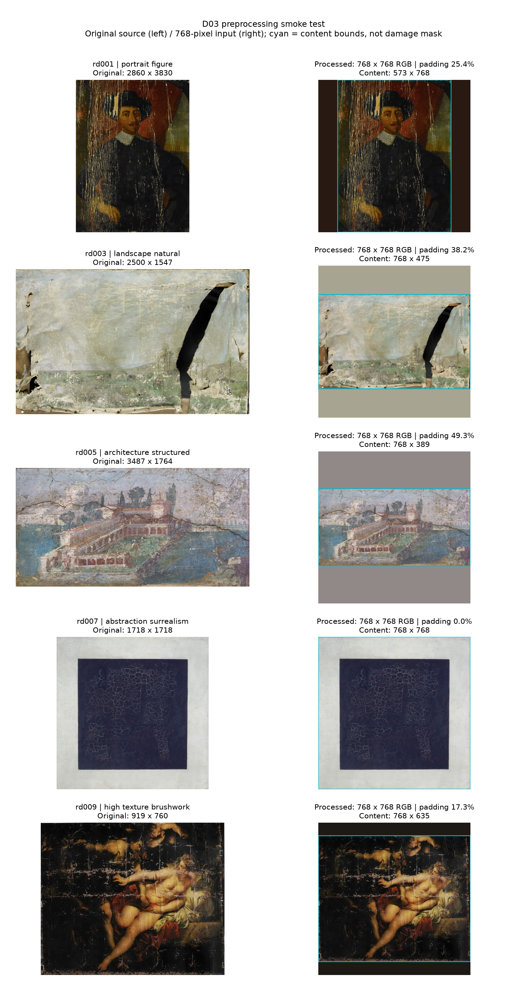

Full-resolution comparison sheet:
D:\Masters\FH\Thesis\painting-restoration-eval\outputs\d03_real_damage_dataset_preparation\work\preprocessing_smoke\preprocessing_preview.png

Individual processed images:
rd001: D:\Masters\FH\Thesis\painting-restoration-eval\outputs\d03_real_damage_dataset_preparation\work\preprocessing_smoke\rd001.png
rd003: D:\Masters\FH\Thesis\painting-restoration-eval\outputs\d03_real_damage_dataset_preparation\work\preprocessing_smoke\rd003.png
rd005: D:\Masters\FH\Thesis\painting-restoration-eval\outputs\d03_real_damage_dataset_preparation\work\preprocessing_smoke\rd005.png
rd007: D:\Masters\FH\Thesis\painting-restoration-eval\outputs\d03_real_damage_dataset_preparation\work\preprocessing_smoke\rd007.png
rd009: D:\Masters\FH\Thesis\painting-restoration-eval\outputs\d03_real_damage_dataset_preparation\work\preprocessing_smoke\rd009.png


In [9]:
if not BATCH_3_READY:
    raise RuntimeError("Pass Batch 3 numerical checks first.")

display(NotebookImage(
    filename=str(SMOKE_PREVIEW_PATH),
    width=950,
))

print("Full-resolution comparison sheet:")
print(SMOKE_PREVIEW_PATH)

print("\nIndividual processed images:")
for row in SMOKE_IMAGES.itertuples(index=False):
    print(f"{row.painting_id}: {PROJECT_ROOT / row.processed_path}")

## Batch 4 — Full preprocessing and selected repair masks

This batch prepares all ten physically damaged inputs using the unchanged
768-pixel preprocessing helper and configuration. The five representative
inputs must match the accepted Batch 3 images byte for byte.

The selected binary masks are loaded from the saved acquisition annotations.
Their source-image, processed-image and mask hashes are verified before use.
No new segmentation thresholds, dilation or changes to selected pixels are
introduced. Antigone (`rd002`) retains the expanded soldier/cliff flaking mask.

Validation covers processed-image format and geometry, source preservation,
binary-mask values, nonempty masks, exclusion of padding and consistency with
the accepted smoke images.

Outputs comprise:

- Ten processed damaged-input images under `images/inputs/`.
- Ten candidate masks under `work/annotation_candidates/masks/`.
- Ten detailed review sheets and one overview.
- Temporary preprocessing and candidate-mask tables.
- A snapshot of the annotation recipe.

The selected masks describe repair targets rather than all physical damage.
Source-selection review is recorded, while final mask approval and
inference-resolution validation remain separate subsequent steps.

No clean references are introduced and no restoration models are run.

In [10]:
BATCH_4_READY = False

if not globals().get("BATCH_3_READY", False):
    raise RuntimeError("The Batch 3 prerequisite is not satisfied.")

import importlib
from restoration_eval import real_damage_preparation

real_damage_preparation = importlib.reload(real_damage_preparation)

BATCH_4_CONTEXT = real_damage_preparation.refresh_preparation_context(
    PROJECT_ROOT,
    CONFIG_PATH,
    previous_config=CONFIG,
    previous_input_checksums=INPUT_CHECKSUMS,
    previous_validation=VALIDATION,
)

CONFIG = BATCH_4_CONTEXT["config"]
SOURCE_CATALOG = BATCH_4_CONTEXT["catalog"]
INPUTS = BATCH_4_CONTEXT["inputs"]
OUTPUTS = BATCH_4_CONTEXT["outputs"]
VALIDATION = BATCH_4_CONTEXT["validation"]
INVENTORY_RUN = BATCH_4_CONTEXT["inventory"]
INPUT_AUDIT = BATCH_4_CONTEXT["input_audit"]
INPUT_CHECKSUMS = BATCH_4_CONTEXT["input_checksums"]

HELPER_VERSIONS["real_damage_preparation"] = (
    real_damage_preparation.REAL_DAMAGE_PREPARATION_MODULE_VERSION
)
SMOKE_VISUAL_REVIEW_STATUS = "accepted_by_user_in_chat"

print("Dataset version:", CONFIG["dataset"]["dataset_version"])
print("Configuration version:", CONFIG["config_version"])
print("Preparation helper:", HELPER_VERSIONS["real_damage_preparation"])
print("Inventory run:", INVENTORY_RUN["inventory_run_id"])
print("Preprocessing review:", SMOKE_VISUAL_REVIEW_STATUS)
print("Retained validation:", VALIDATION.summary())

Dataset version: 2.0.0
Configuration version: 2.0.1
Preparation helper: 1.1.1
Inventory run: inventory_20261114T235314Z_82353568
Preprocessing review: accepted_by_user_in_chat
Retained validation: {'check_count': 144, 'passed_count': 144, 'failed_count': 0, 'blocking_failure_count': 0, 'overall_passed': True, 'failed_check_ids': []}


In [11]:
BATCH_4_READY = False

PREPARATION_RESULT = real_damage_preparation.prepare_real_damage_inputs(
    PROJECT_ROOT,
    CONFIG,
    SOURCE_CATALOG,
    ARTWORKS,
    PREPROCESSING_CONFIG,
    SMOKE_IMAGES,
    previous_validation=VALIDATION,
    progress_callback=lambda event: print(
        f"[{event['completed']}/{event['total']} | "
        f"{event['percentage']}%] "
        f"{event['painting_id']} | "
        f"{'reused' if event['reused'] else 'written'} | "
        f"{event['elapsed_seconds']:.1f} seconds"
    ),
)

VALIDATION = PREPARATION_RESULT["validation"]
PREPROCESSED_IMAGES = PREPARATION_RESULT["preprocessed_images"]
MASK_CANDIDATES = PREPARATION_RESULT["mask_candidates"]
CANDIDATE_ATLAS_PATH = PREPARATION_RESULT["atlas_path"]
ANNOTATION_WORK_ROOT = PREPARATION_RESULT["work_root"]

print("Processed inputs:", len(PREPROCESSED_IMAGES))
print("Candidate masks:", len(MASK_CANDIDATES))
print("Final review status:", PREPARATION_RESULT["review_status"])
print("Annotation recipe SHA-256:", PREPARATION_RESULT["recipe_sha256"])
print("Active time:", round(PREPARATION_RESULT["elapsed_seconds"], 2), "seconds")
print("Candidate work directory:", ANNOTATION_WORK_ROOT)

[1/10 | 10%] rd001 | written | 9.6 seconds
[2/10 | 20%] rd002 | written | 10.7 seconds
[3/10 | 30%] rd003 | written | 12.0 seconds
[4/10 | 40%] rd004 | written | 13.1 seconds
[5/10 | 50%] rd005 | written | 14.3 seconds
[6/10 | 60%] rd006 | written | 15.4 seconds
[7/10 | 70%] rd007 | written | 16.7 seconds
[8/10 | 80%] rd008 | written | 17.9 seconds
[9/10 | 90%] rd009 | written | 19.2 seconds
[10/10 | 100%] rd010 | written | 21.0 seconds
Processed inputs: 10
Candidate masks: 10
Final review status: pending
Annotation recipe SHA-256: 11f0ecc1cad6489fd8dc4907c89e81ae49f6f0efd3f0bdbcf070254e9aac9f6d
Active time: 23.79 seconds
Candidate work directory: D:\Masters\FH\Thesis\painting-restoration-eval\outputs\d03_real_damage_dataset_preparation\work\annotation_candidates


In [12]:
BATCH_4_READY = False

BATCH_4_CHECKS = show_validation_stage(
    real_damage_preparation.PREPARATION_STAGE
)
BATCH_4_READY = True

print("Processed-image geometry")
display(PREPROCESSED_IMAGES[
    [
        "painting_id",
        "category",
        "resized_width",
        "resized_height",
        "pad_left",
        "pad_top",
        "pad_right",
        "pad_bottom",
        "processed_path",
    ]
])

print("Selected repair coverage, excluding padding")
display(
    MASK_CANDIDATES.assign(
        masked_content_percent=(
            MASK_CANDIDATES["mask_fraction_content"] * 100
        ).round(4)
    )[
        [
            "painting_id",
            "mask_pixel_count",
            "masked_content_percent",
            "review_status",
            "candidate_is_final",
        ]
    ]
)

print("Combined validation:", VALIDATION.summary())

,stage,checks,passed,failed
0,batch_4_preprocessing_and_mask_candidates,63,63,0


Processed-image geometry


,painting_id,category,resized_width,resized_height,pad_left,pad_top,pad_right,pad_bottom,processed_path
0,rd001,portrait_figure,573,768,97,0,98,0,outputs/d03_real_damage_dataset_preparation/im...
1,rd002,portrait_figure,768,539,0,114,0,115,outputs/d03_real_damage_dataset_preparation/im...
2,rd003,landscape_natural,768,475,0,146,0,147,outputs/d03_real_damage_dataset_preparation/im...
3,rd004,landscape_natural,768,447,0,160,0,161,outputs/d03_real_damage_dataset_preparation/im...
4,rd005,architecture_structured,768,389,0,189,0,190,outputs/d03_real_damage_dataset_preparation/im...
5,rd006,architecture_structured,768,406,0,181,0,181,outputs/d03_real_damage_dataset_preparation/im...
6,rd007,abstraction_surrealism,768,768,0,0,0,0,outputs/d03_real_damage_dataset_preparation/im...
7,rd008,abstraction_surrealism,768,556,0,106,0,106,outputs/d03_real_damage_dataset_preparation/im...
8,rd009,high_texture_brushwork,768,635,0,66,0,67,outputs/d03_real_damage_dataset_preparation/im...
9,rd010,high_texture_brushwork,515,768,126,0,127,0,outputs/d03_real_damage_dataset_preparation/im...


Selected repair coverage, excluding padding


,painting_id,mask_pixel_count,masked_content_percent,review_status,candidate_is_final
0,rd001,12122,2.7546,pending,False
1,rd002,14486,3.4994,pending,False
2,rd003,26300,7.2094,pending,False
3,rd004,21872,6.3712,pending,False
4,rd005,6449,2.1586,pending,False
5,rd006,8532,2.7363,pending,False
6,rd007,46168,7.8274,pending,False
7,rd008,8646,2.0248,pending,False
8,rd009,12540,2.5714,pending,False
9,rd010,14533,3.6744,pending,False


Combined validation: {'check_count': 207, 'passed_count': 207, 'failed_count': 0, 'blocking_failure_count': 0, 'overall_passed': True, 'failed_check_ids': []}


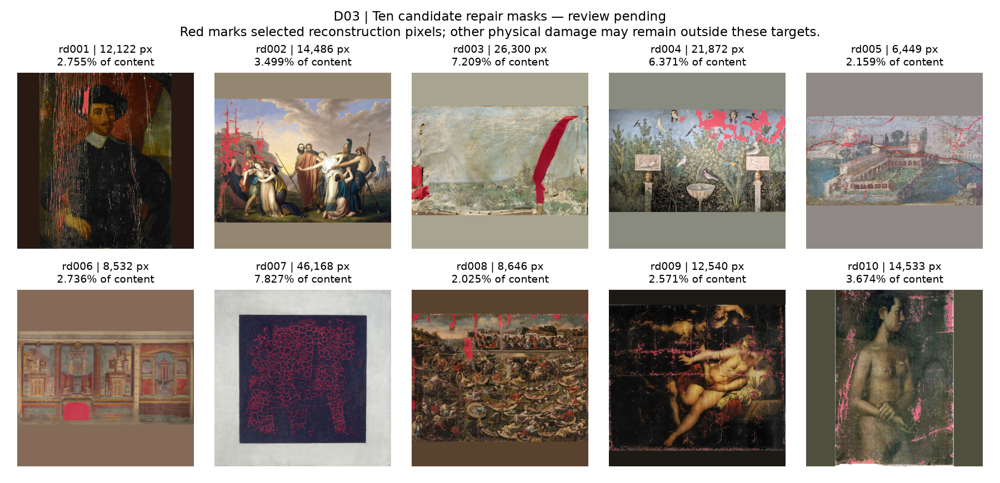

Candidate-mask overview: D:\Masters\FH\Thesis\painting-restoration-eval\outputs\d03_real_damage_dataset_preparation\work\annotation_candidates\mask_candidates_atlas.png


,painting_id,target_description,selection_notes,preview_path
0,rd001,"Visible vertical losses across the background, hat and clothing. Review mask targets clear losses; it is not exhaustive condition mapping. The broader uniform loss on the hat has been included.","Other physical deterioration may remain outside the repair mask; it is outside this restoration target, not automatically model failure. No clean reference exists.",outputs/d03_real_damage_dataset_preparation/work/annotation_candidates/previews/rd001.png
1,rd002,"Visible flaking across the left background, cliff and soldier. Expanded after user review to include the breastplate and branching cliff losses. Intact skin, metal, architecture and spear are excluded where distinguishable. No dilation or damage synthesis.","Other physical deterioration may remain outside the repair mask; it is outside this restoration target, not automatically model failure. No clean reference exists.",outputs/d03_real_damage_dataset_preparation/work/annotation_candidates/previews/rd002.png
2,rd003,Large open tear on the right and smaller open losses at the left edge. Broader surface abrasion is present outside the selected repair targets; this mask is not a claim that all physical damage occupies only 7.21%.,"Other physical deterioration may remain outside the repair mask; it is outside this restoration target, not automatically model failure. No clean reference exists.",outputs/d03_real_damage_dataset_preparation/work/annotation_candidates/previews/rd003.png
3,rd004,"Visible neutral-filled lacunae interrupt the blue sky and foliage. Targets are missing painted content within the panel; ornamental heads, birds and painted pale surfaces are excluded. This is a painted garden, rather than an oil landscape. Photo: Tyler Bell; CC BY 2.0.","Other physical deterioration may remain outside the repair mask; it is outside this restoration target, not automatically model failure. No clean reference exists. Prior neutral fills/retouching are present; do not describe the photograph as untreated fresh damage.",outputs/d03_real_damage_dataset_preparation/work/annotation_candidates/previews/rd004.png
4,rd005,Selected fracture network and an exposed loss at a crack junction. Pale architecture is preserved. Some abrasion and fine cracks remain outside the repair target. Photograph: BeakheadIntrados; CC BY-SA 4.0.,"Other physical deterioration may remain outside the repair mask; it is outside this restoration target, not automatically model failure. No clean reference exists.",outputs/d03_real_damage_dataset_preparation/work/annotation_candidates/previews/rd005.png
5,rd006,"Selected lower central neutral infill/lacuna. Historical photographs show loss in this lower dado, and the museum conservation report describes fills and retouching. This is not untreated fresh damage: the target lacks depicted content, while other repaired or abraded areas remain. Source: The Met, CC0.","Other physical deterioration may remain outside the repair mask; it is outside this restoration target, not automatically model failure. No clean reference exists. Prior neutral fills/retouching are present; do not describe the photograph as untreated fresh damage.",outputs/d03_real_damage_dataset_preparation/work/annotation_candidates/previews/rd006.png
6,rd007,"Local contrast selection across the visible crack network in the black field. No dilation; a selected digital repair target, not conservator-validated condition mapping.","Other physical deterioration may remain outside the repair mask; it is outside this restoration target, not automatically model failure. No clean reference exists.",outputs/d03_real_damage_dataset_preparation/work/annotation_candidates/previews/rd007.png
7,rd008,"Selected exposed-ground losses near the upper edge plus a visibly worn vertical zone. Not a complete condition map. The category is fantastical imagery, not a claim that this 18th-century work belongs to historical Surrealism. Coverage is close to 2

In [13]:
if not BATCH_4_READY:
    raise RuntimeError("Batch 4 validation is incomplete.")

display(NotebookImage(
    filename=str(CANDIDATE_ATLAS_PATH),
    width=1100,
))

print("Candidate-mask overview:", CANDIDATE_ATLAS_PATH)

with pd.option_context("display.max_colwidth", None):
    display(MASK_CANDIDATES[
        [
            "painting_id",
            "target_description",
            "selection_notes",
            "preview_path",
        ]
    ])

Painting: rd005
Repair target: Selected fracture network and an exposed loss at a crack junction. Pale architecture is preserved. Some abrasion and fine cracks remain outside the repair target. Photograph: BeakheadIntrados; CC BY-SA 4.0.
Selection notes: Other physical deterioration may remain outside the repair mask; it is outside this restoration target, not automatically model failure. No clean reference exists.
Selected pixels: 6449
Selected content: 2.1586%


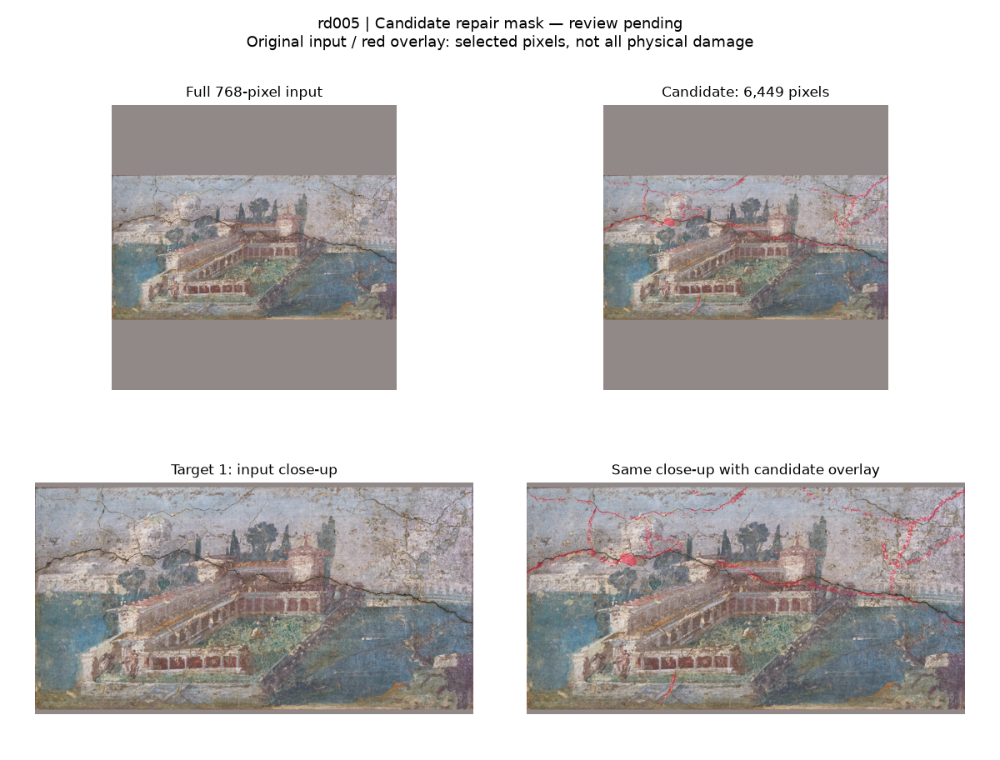

In [15]:
if not BATCH_4_READY:
    raise RuntimeError("Batch 4 validation is incomplete.")

REVIEW_PAINTING_ID = "rd005"

selected_candidate = MASK_CANDIDATES.loc[
    MASK_CANDIDATES["painting_id"].eq(REVIEW_PAINTING_ID)
]

if len(selected_candidate) != 1:
    raise ValueError(
        f"Expected one mask candidate for {REVIEW_PAINTING_ID}; "
        f"found {len(selected_candidate)}."
    )

candidate = selected_candidate.iloc[0]

print("Painting:", candidate["painting_id"])
print("Repair target:", candidate["target_description"])
print("Selection notes:", candidate["selection_notes"])
print("Selected pixels:", int(candidate["mask_pixel_count"]))
print(
    "Selected content:",
    f"{candidate['mask_fraction_content']:.4%}",
)

display(NotebookImage(
    filename=str(PROJECT_ROOT / candidate["preview_path"]),
    width=1000,
))

## Batch 5 — Mask approval and inference-scale review

This batch records the researcher's acceptance of the ten selected repair
masks from Batch 4. Approval is bound to the exact processed-image and mask
hashes. These masks describe selected reconstruction targets, rather than
exhaustive maps of physical damage.

The canonical masks remain at 768 × 768 pixels. A separate diagnostic
examines their nearest-neighbour resizing to 512 × 512 pixels, matching
the existing Stable Diffusion mask-resizing policy. No dilation or
additional damage selection is applied.

The diagnostic records:

- Selected coverage relative to image content at both resolutions.
- Connected components that disappear completely during resizing.
- The proportion of selected source pixels belonging to those components.
- Mask changes after resizing from 768 to 512 and back to 768 pixels.
- Whether the inference mask becomes empty or overlaps resized padding.

Round-trip intersection over union measures agreement between mask
geometries; it is not a restoration-quality score. Disappearing components
also do not describe every resizing change: surviving components can
change shape or thickness.

Review sheets show the original mask, its inference-resolution counterpart
and completely lost components, with matching enlarged details.

The accepted 768-pixel masks and the pending 512-pixel review are recorded
separately. Passing technical validation does not grant model eligibility.
Review tables, diagnostic masks and previews are saved as temporary
checkpoints under `work/mask_review/`. No restoration is performed.

In [16]:
BATCH_5_READY = False

if not globals().get("BATCH_4_READY", False):
    raise RuntimeError("The Batch 4 prerequisite is not satisfied.")

import importlib
from restoration_eval import real_damage_review

real_damage_review = importlib.reload(real_damage_review)

BATCH_5_CONTEXT = real_damage_preparation.refresh_preparation_context(
    PROJECT_ROOT,
    CONFIG_PATH,
    previous_config=CONFIG,
    previous_input_checksums=INPUT_CHECKSUMS,
    previous_validation=VALIDATION,
)

CONFIG = BATCH_5_CONTEXT["config"]
SOURCE_CATALOG = BATCH_5_CONTEXT["catalog"]
INPUTS = BATCH_5_CONTEXT["inputs"]
OUTPUTS = BATCH_5_CONTEXT["outputs"]
VALIDATION = BATCH_5_CONTEXT["validation"]
INVENTORY_RUN = BATCH_5_CONTEXT["inventory"]
INPUT_AUDIT = BATCH_5_CONTEXT["input_audit"]
INPUT_CHECKSUMS = BATCH_5_CONTEXT["input_checksums"]

HELPER_VERSIONS["real_damage_review"] = (
    real_damage_review.REAL_DAMAGE_REVIEW_MODULE_VERSION
)

print("Dataset version:", CONFIG["dataset"]["dataset_version"])
print("Configuration version:", CONFIG["config_version"])
print("Review helper:", HELPER_VERSIONS["real_damage_review"])
print("Inventory run:", INVENTORY_RUN["inventory_run_id"])
print("Retained validation:", VALIDATION.summary())

Dataset version: 2.0.0
Configuration version: 2.1.0
Review helper: 1.0.0
Inventory run: inventory_20261115T000931Z_03117d8b
Retained validation: {'check_count': 207, 'passed_count': 207, 'failed_count': 0, 'blocking_failure_count': 0, 'overall_passed': True, 'failed_check_ids': []}


In [17]:
BATCH_5_READY = False

MASK_REVIEW_RESULT = real_damage_review.review_real_damage_masks(
    PROJECT_ROOT,
    CONFIG,
    PREPROCESSED_IMAGES,
    MASK_CANDIDATES,
    previous_validation=VALIDATION,
    progress_callback=lambda event: print(
        f"[{event['completed']}/{event['total']}] "
        f"{event['painting_id']} | "
        f"{event['phase']} | "
        f"{event['elapsed_seconds']:.1f} seconds"
    ),
)

VALIDATION = MASK_REVIEW_RESULT["validation"]
MASK_REVIEW = MASK_REVIEW_RESULT["mask_review"]
INFERENCE_MASK_AUDIT = MASK_REVIEW_RESULT["inference_mask_audit"]
MASK_REVIEW_WORK_ROOT = MASK_REVIEW_RESULT["work_root"]

print("Recorded 768-pixel mask reviews:", len(MASK_REVIEW))
print("Inference-scale diagnostics:", len(INFERENCE_MASK_AUDIT))
print(
    "Empty 512-pixel masks:",
    int(INFERENCE_MASK_AUDIT["empty_inference_mask"].sum()),
)
print("Scale review:", MASK_REVIEW_RESULT["scale_review_status"])
print(
    "Active time:",
    round(MASK_REVIEW_RESULT["elapsed_seconds"], 2),
    "seconds",
)
print("Review checkpoint:", MASK_REVIEW_RESULT["review_checkpoint_path"])

[1/10] rd001 | validated | 1.5 seconds
[2/10] rd002 | validated | 2.9 seconds
[3/10] rd003 | validated | 4.2 seconds
[4/10] rd004 | validated | 5.6 seconds
[5/10] rd005 | validated | 7.0 seconds
[6/10] rd006 | validated | 8.3 seconds
[7/10] rd007 | validated | 9.9 seconds
[8/10] rd008 | validated | 11.2 seconds
[9/10] rd009 | validated | 12.6 seconds
[10/10] rd010 | validated | 14.0 seconds
Recorded 768-pixel mask reviews: 10
Inference-scale diagnostics: 10
Empty 512-pixel masks: 0
Scale review: pending
Active time: 14.13 seconds
Review checkpoint: D:\Masters\FH\Thesis\painting-restoration-eval\outputs\d03_real_damage_dataset_preparation\work\mask_review\review_checkpoint.json


In [18]:
BATCH_5_READY = False

BATCH_5_CHECKS = show_validation_stage(
    real_damage_review.REVIEW_STAGE
)
BATCH_5_READY = True

print("Researcher approval of selected 768-pixel repair targets")
display(MASK_REVIEW[
    [
        "painting_id",
        "review_status",
        "reviewer",
        "review_scope",
        "scale_review_status",
    ]
])

SCALE_COVERAGE = INFERENCE_MASK_AUDIT.assign(
    mask_768_percent=(
        INFERENCE_MASK_AUDIT["source_content_fraction"] * 100
    ).round(4),
    mask_512_percent=(
        INFERENCE_MASK_AUDIT["inference_content_fraction"] * 100
    ).round(4),
    change_percentage_points=(
        INFERENCE_MASK_AUDIT[
            "content_fraction_change_percentage_points"
        ]
    ).round(4),
)

print("Selected coverage relative to image content")
display(SCALE_COVERAGE[
    [
        "painting_id",
        "mask_768_percent",
        "mask_512_percent",
        "change_percentage_points",
        "empty_inference_mask",
    ]
])

SCALE_GEOMETRY = INFERENCE_MASK_AUDIT.assign(
    selected_pixels_in_lost_components_percent=(
        INFERENCE_MASK_AUDIT["disappeared_source_pixel_fraction"] * 100
    ).round(4),
    mask_roundtrip_iou=(
        INFERENCE_MASK_AUDIT["roundtrip_iou"]
    ).round(4),
)

print("Component survival and mask geometry")
display(SCALE_GEOMETRY[
    [
        "painting_id",
        "source_component_count",
        "disappeared_component_count",
        "disappeared_source_pixels",
        "selected_pixels_in_lost_components_percent",
        "mask_roundtrip_iou",
        "scale_review_status",
    ]
])

print("Combined validation:", VALIDATION.summary())

,stage,checks,passed,failed
0,batch_5_mask_review_and_inference_scale,43,43,0


Researcher approval of selected 768-pixel repair targets


,painting_id,review_status,reviewer,review_scope,scale_review_status
0,rd001,approved,Rahul Maddineni,selected_repair_targets_only,pending
1,rd002,approved,Rahul Maddineni,selected_repair_targets_only,pending
2,rd003,approved,Rahul Maddineni,selected_repair_targets_only,pending
3,rd004,approved,Rahul Maddineni,selected_repair_targets_only,pending
4,rd005,approved,Rahul Maddineni,selected_repair_targets_only,pending
5,rd006,approved,Rahul Maddineni,selected_repair_targets_only,pending
6,rd007,approved,Rahul Maddineni,selected_repair_targets_only,pending
7,rd008,approved,Rahul Maddineni,selected_repair_targets_only,pending
8,rd009,approved,Rahul Maddineni,selected_repair_targets_only,pending
9,rd010,approved,Rahul Maddineni,selected_repair_targets_only,pending


Selected coverage relative to image content


,painting_id,mask_768_percent,mask_512_percent,change_percentage_points,empty_inference_mask
0,rd001,2.7546,2.7691,0.0145,False
1,rd002,3.4994,3.5205,0.0211,False
2,rd003,7.2094,7.1970,-0.0124,False
3,rd004,6.3712,6.3693,-0.0019,False
4,rd005,2.1586,2.1673,0.0086,False
5,rd006,2.7363,2.7221,-0.0142,False
6,rd007,7.8274,7.8407,0.0133,False
7,rd008,2.0248,2.0466,0.0218,False
8,rd009,2.5714,2.6037,0.0323,False
9,rd010,3.6744,3.6785,0.0041,False


Component survival and mask geometry


,painting_id,source_component_count,disappeared_component_count,disappeared_source_pixels,selected_pixels_in_lost_components_percent,mask_roundtrip_iou,scale_review_status
0,rd001,669,71,416,3.4318,0.6374,pending
1,rd002,151,11,37,0.2554,0.8214,pending
2,rd003,3,0,0,0.0000,0.9796,pending
3,rd004,6,0,0,0.0000,0.9415,pending
4,rd005,370,100,144,2.2329,0.6323,pending
5,rd006,1,0,0,0.0000,0.9757,pending
6,rd007,1006,12,55,0.1191,0.6390,pending
7,rd008,12,0,0,0.0000,0.9413,pending
8,rd009,1394,340,546,4.3541,0.5946,pending
9,rd010,1002,317,467,3.2134,0.6995,pending


Combined validation: {'check_count': 250, 'passed_count': 250, 'failed_count': 0, 'blocking_failure_count': 0, 'overall_passed': True, 'failed_check_ids': []}


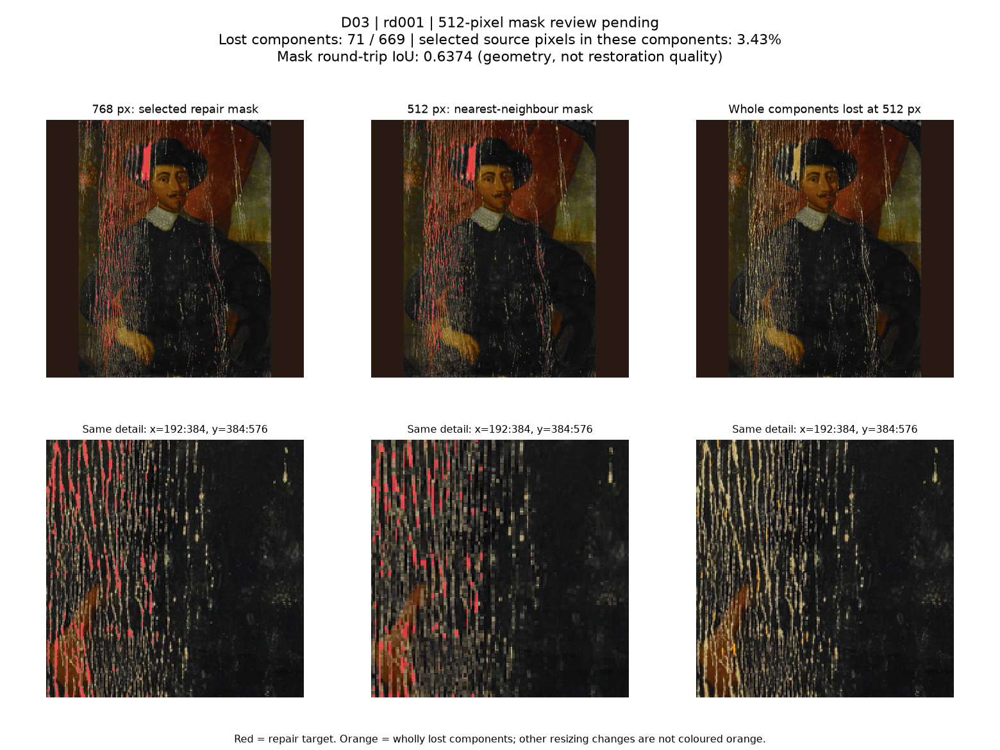

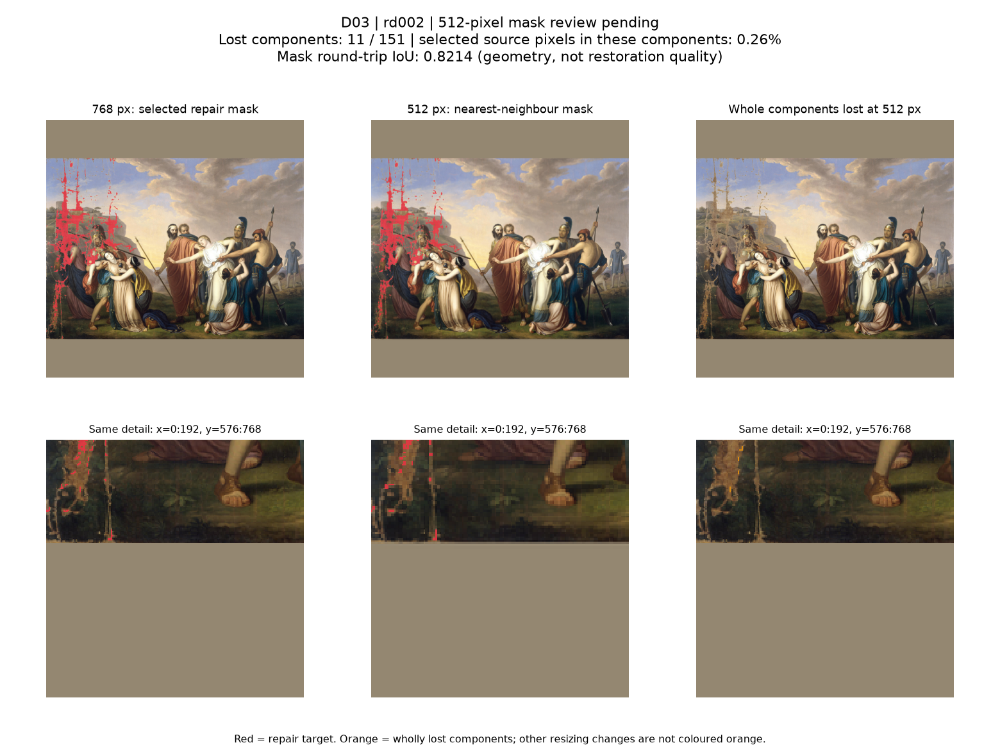

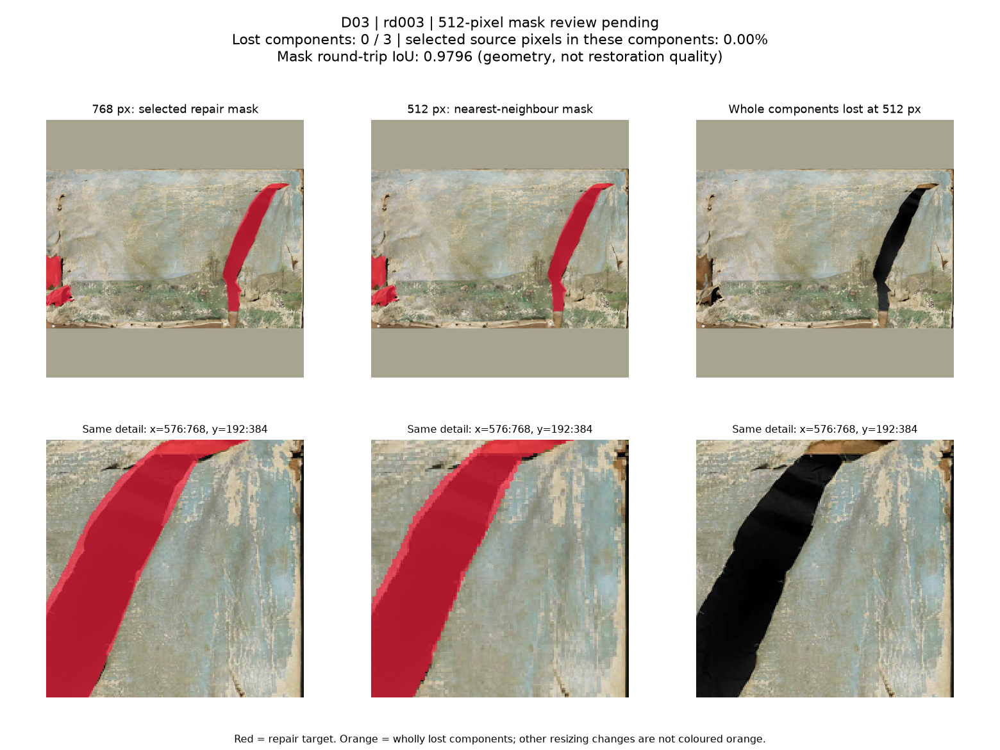

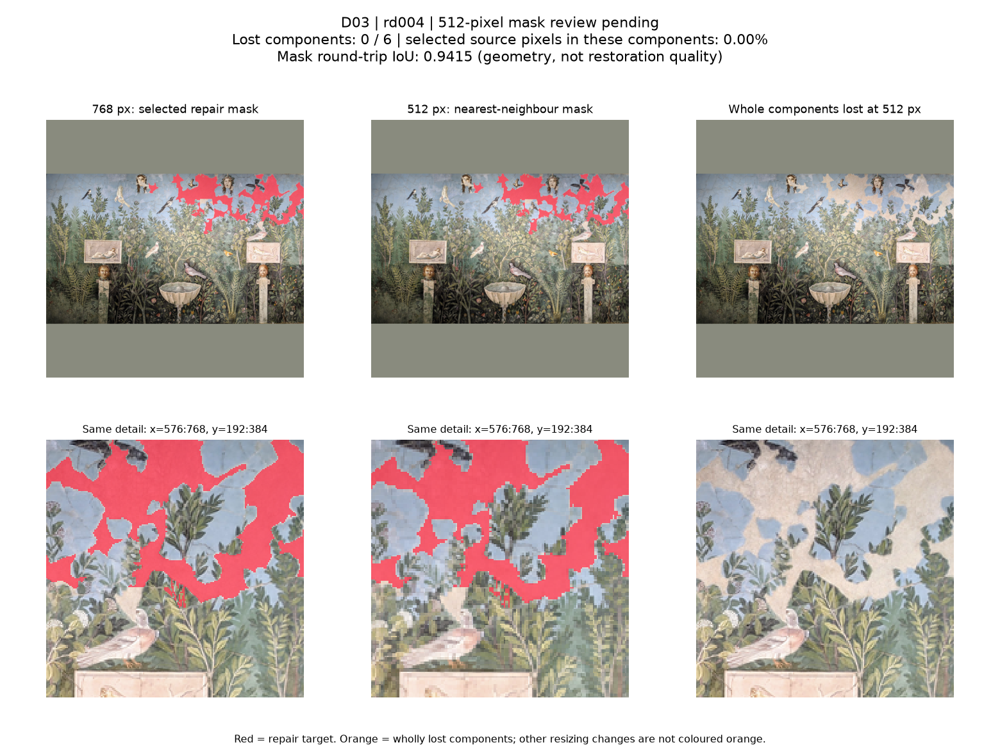

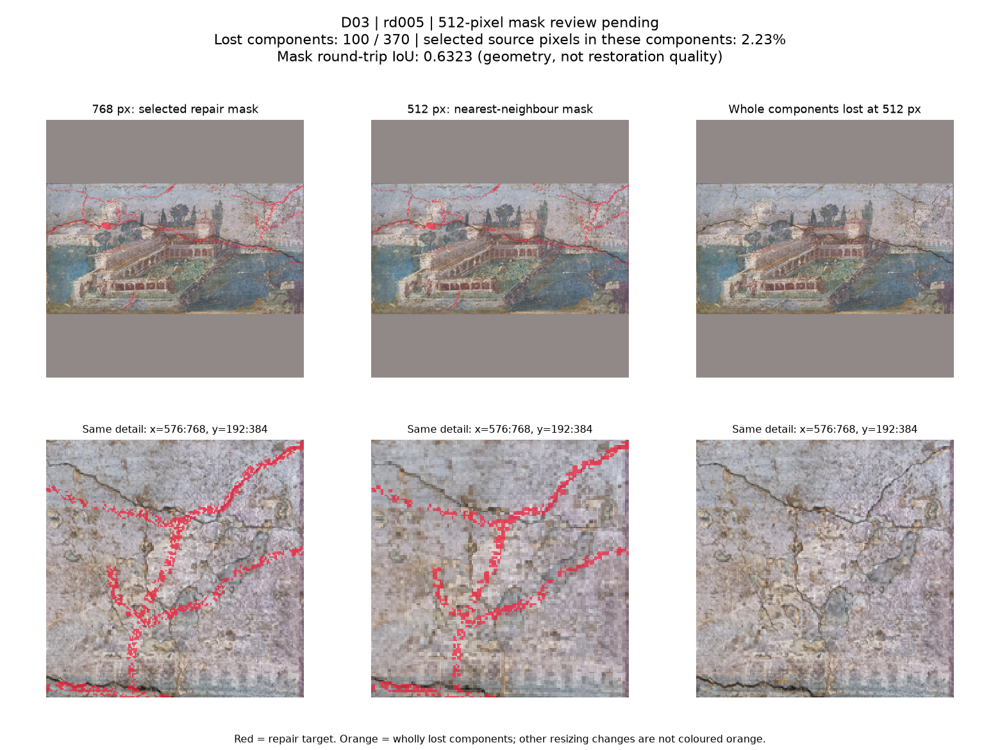

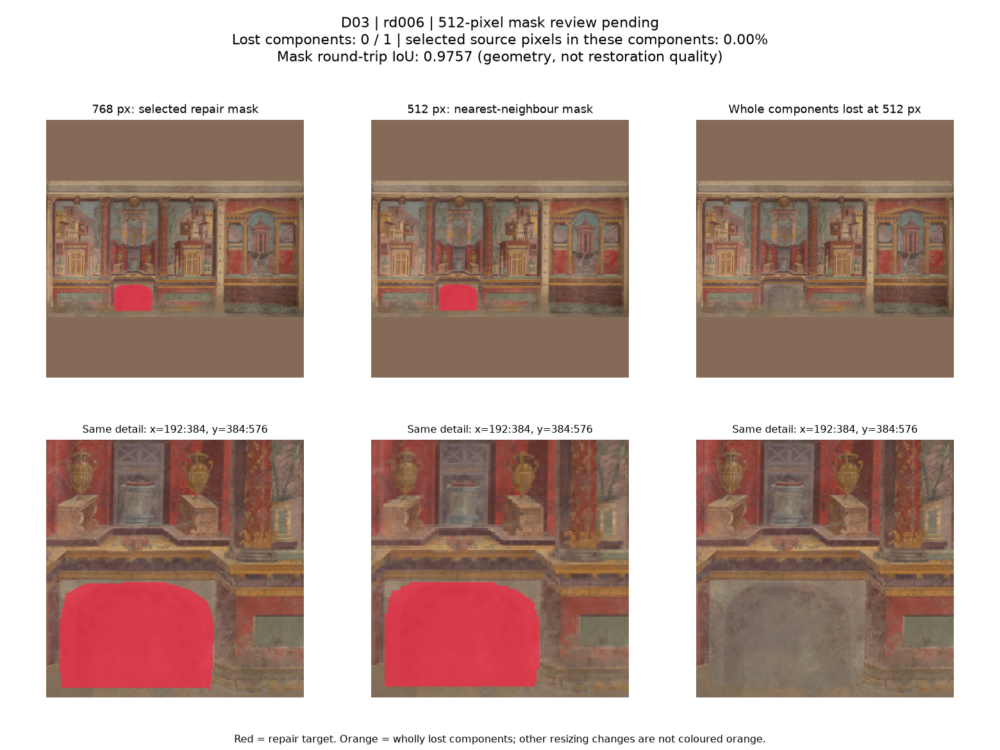

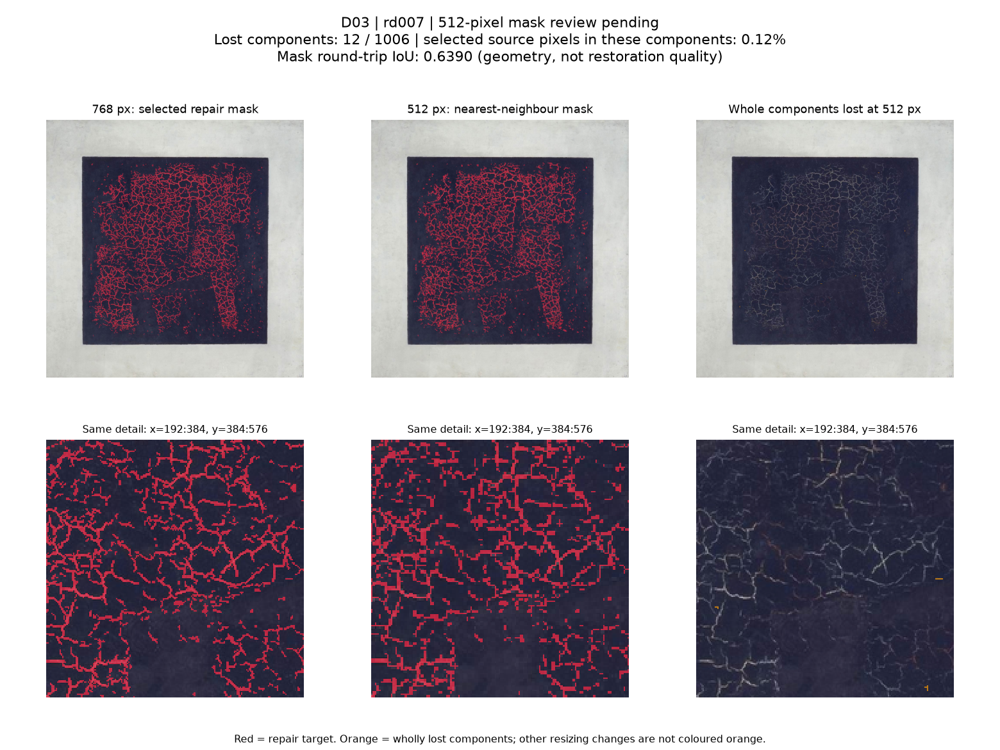

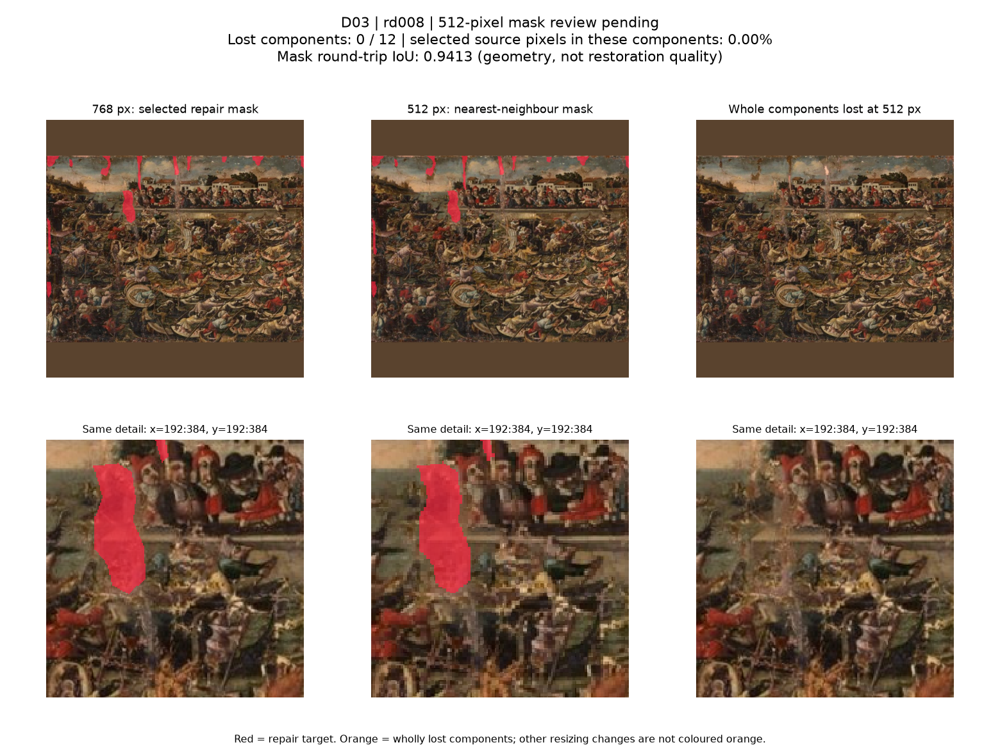

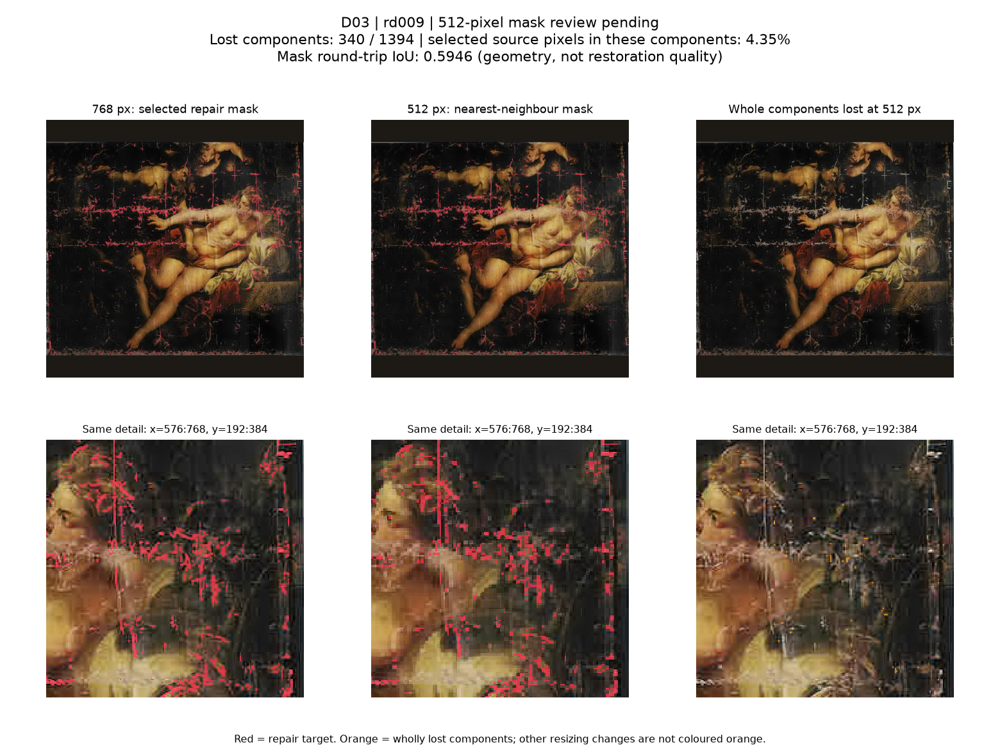

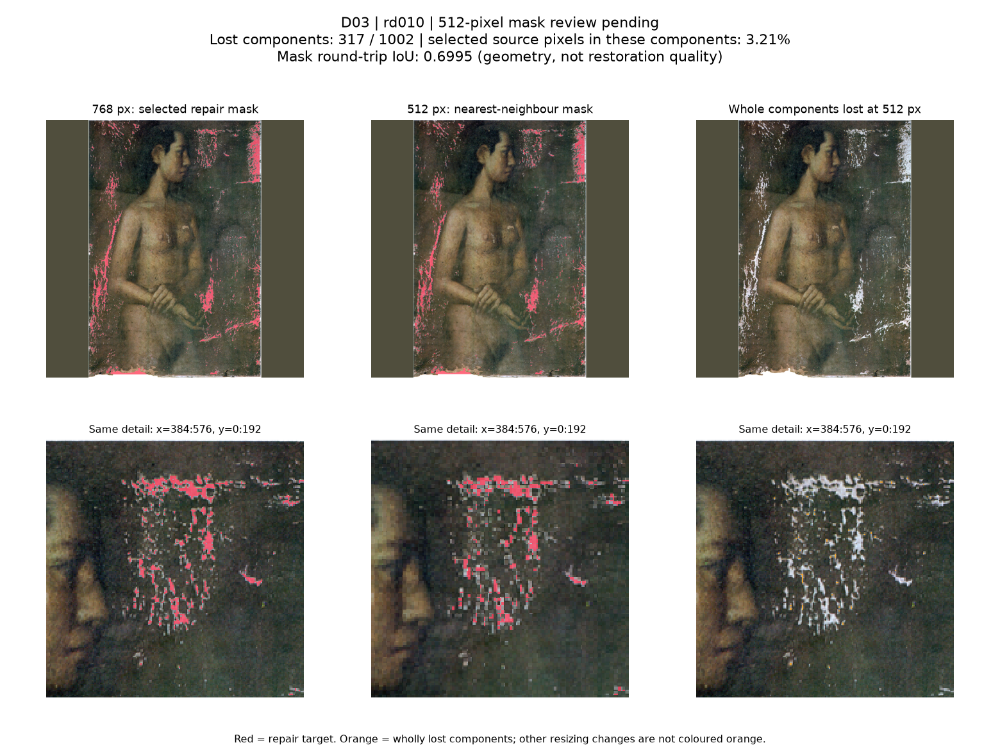

Saved review sheets: D:\Masters\FH\Thesis\painting-restoration-eval\outputs\d03_real_damage_dataset_preparation\work\mask_review\previews


In [19]:
if not BATCH_5_READY:
    raise RuntimeError("Batch 5 technical validation is incomplete.")

for scale_record in INFERENCE_MASK_AUDIT.itertuples(index=False):
    display(NotebookImage(
        filename=str(PROJECT_ROOT / scale_record.preview_path),
        width=1100,
    ))

print("Saved review sheets:", MASK_REVIEW_WORK_ROOT / "previews")

## Batch 6 — Mask geometry and model eligibility

This batch incorporates the researcher's acceptance of the Batch 5
inference-scale previews. The decision is bound to the saved review
artifacts and the input, canonical-mask and inference-mask hashes.

Mask geometry is calculated using the existing morphology helper.
Measurements include selected area, connected components, bounding-box
geometry, perimeter and contact with the image-content boundary.

The existing region policy defines the mask crop, boundary bands and
outside-mask content. These regions describe spatial support; their
availability does not create a clean reference for physically damaged
paintings.

Ten case records retain the source, processed-image and mask identities.
Case identifiers include the cohort version and a hash of those inputs,
so reused painting IDs cannot silently identify different experiments.

An eligibility matrix contains one row for each case and each of the
four methods: OpenCV Telea, LaMa, HINT and Stable Diffusion. The existing
model configurations and binary-mask threshold remain unchanged.
Stable Diffusion additionally requires a nonempty 512-pixel mask and
accepted inference-scale effects.

Eligibility means input and mask compatibility. Model loading, weights,
hardware availability and successful inference are checked in D04.

No damaged input is treated as a clean reference. Reference-fidelity
metrics remain inapplicable to the unknown original content.

Six prepared tables and a checkpoint are saved under
`work/geometry_eligibility/`. Canonical publication follows in Batch 7,
and downstream readiness requires the Batch 8 completion gate.

In [20]:
BATCH_6_READY = False

if not globals().get("BATCH_5_READY", False):
    raise RuntimeError("The Batch 5 prerequisite is not satisfied.")

import importlib
from restoration_eval import real_damage_eligibility

real_damage_eligibility = importlib.reload(real_damage_eligibility)

ELIGIBILITY_CONFIG_PATH = (
    PROJECT_ROOT / "config/datasets/real_damage_eligibility.yaml"
)

BATCH_6_CONTEXT = (
    real_damage_eligibility.refresh_eligibility_context(
        PROJECT_ROOT,
        CONFIG_PATH,
        ELIGIBILITY_CONFIG_PATH,
        previous_config=CONFIG,
        previous_input_checksums=INPUT_CHECKSUMS,
        previous_validation=VALIDATION,
    )
)

CONFIG = BATCH_6_CONTEXT["config"]
ELIGIBILITY_CONFIG = BATCH_6_CONTEXT["eligibility_config"]
SOURCE_CATALOG = BATCH_6_CONTEXT["catalog"]
INPUTS = BATCH_6_CONTEXT["inputs"]
OUTPUTS = BATCH_6_CONTEXT["outputs"]
VALIDATION = BATCH_6_CONTEXT["validation"]
INVENTORY_RUN = BATCH_6_CONTEXT["inventory"]
INPUT_AUDIT = BATCH_6_CONTEXT["input_audit"]
INPUT_CHECKSUMS = BATCH_6_CONTEXT["input_checksums"]

HELPER_VERSIONS["real_damage_eligibility"] = (
    real_damage_eligibility.REAL_DAMAGE_ELIGIBILITY_MODULE_VERSION
)

print("Preparation configuration:", CONFIG["config_version"])
print("Eligibility configuration:", ELIGIBILITY_CONFIG["config_version"])
print("Eligibility helper:", HELPER_VERSIONS["real_damage_eligibility"])
print("Declared inputs:", len(INPUTS))
print("Inventory run:", INVENTORY_RUN["inventory_run_id"])
print("Retained validation:", VALIDATION.summary())

Preparation configuration: 2.1.0
Eligibility configuration: 1.0.0
Eligibility helper: 1.0.0
Declared inputs: 65
Inventory run: inventory_20261115T002633Z_bba94a35
Retained validation: {'check_count': 250, 'passed_count': 250, 'failed_count': 0, 'blocking_failure_count': 0, 'overall_passed': True, 'failed_check_ids': []}


In [21]:
BATCH_6_READY = False

GEOMETRY_ELIGIBILITY_RESULT = (
    real_damage_eligibility.prepare_geometry_and_eligibility(
        PROJECT_ROOT,
        CONFIG,
        ELIGIBILITY_CONFIG,
        SOURCE_CATALOG,
        ARTWORKS,
        PREPROCESSED_IMAGES,
        MASK_REVIEW_RESULT["mask_review"],
        MASK_REVIEW_RESULT["inference_mask_audit"],
        previous_validation=VALIDATION,
        progress_callback=lambda event: print(
            f"[{event['completed']}/{event['total']}] "
            f"{event['painting_id']} | "
            f"{event['elapsed_seconds']:.1f} seconds"
        ),
    )
)

VALIDATION = GEOMETRY_ELIGIBILITY_RESULT["validation"]
MASKS = GEOMETRY_ELIGIBILITY_RESULT["masks"]
MASK_GEOMETRY = GEOMETRY_ELIGIBILITY_RESULT["mask_geometry"]
MASK_REVIEW = GEOMETRY_ELIGIBILITY_RESULT["mask_review"]
INFERENCE_MASK_AUDIT = (
    GEOMETRY_ELIGIBILITY_RESULT["inference_mask_audit"]
)
CASE_REGISTRY = GEOMETRY_ELIGIBILITY_RESULT["case_registry"]
MODEL_ELIGIBILITY = GEOMETRY_ELIGIBILITY_RESULT["model_eligibility"]
ELIGIBILITY_WORK_ROOT = GEOMETRY_ELIGIBILITY_RESULT["work_root"]

print("Prepared masks:", len(MASKS))
print("Case records:", len(CASE_REGISTRY))
print("Case–model eligibility rows:", len(MODEL_ELIGIBILITY))
print("Eligible rows:", int(MODEL_ELIGIBILITY["eligible"].sum()))
print(
    "Active time:",
    round(GEOMETRY_ELIGIBILITY_RESULT["elapsed_seconds"], 2),
    "seconds",
)
print("Checkpoint:", GEOMETRY_ELIGIBILITY_RESULT["checkpoint_path"])

[1/10] rd001 | 0.8 seconds
[2/10] rd002 | 1.3 seconds
[3/10] rd003 | 1.9 seconds
[4/10] rd004 | 2.5 seconds
[5/10] rd005 | 3.0 seconds
[6/10] rd006 | 3.5 seconds
[7/10] rd007 | 4.4 seconds
[8/10] rd008 | 5.0 seconds
[9/10] rd009 | 5.7 seconds
[10/10] rd010 | 6.7 seconds
Prepared masks: 10
Case records: 10
Case–model eligibility rows: 40
Eligible rows: 40
Active time: 6.82 seconds
Checkpoint: D:\Masters\FH\Thesis\painting-restoration-eval\outputs\d03_real_damage_dataset_preparation\work\geometry_eligibility\eligibility_checkpoint.json


In [22]:
BATCH_6_READY = False

BATCH_6_CHECKS = show_validation_stage(
    real_damage_eligibility.ELIGIBILITY_STAGE
)
BATCH_6_READY = True

GEOMETRY_SUMMARY = MASK_GEOMETRY.assign(
    selected_content_percent=(
        MASK_GEOMETRY["damaged_content_fraction"] * 100
    ).round(4),
    largest_component_percent=(
        MASK_GEOMETRY["largest_component_fraction"] * 100
    ).round(2),
)

print("Selected coverage and component structure")
display(GEOMETRY_SUMMARY[
    [
        "painting_id",
        "selected_content_percent",
        "connected_component_count",
        "largest_component_percent",
        "touches_content_boundary",
        "padding_overlap_pixels",
    ]
])

print("Evaluation-region sizes in pixels")
display(MASK_GEOMETRY[
    [
        "painting_id",
        "content_region_pixels",
        "masked_region_pixels",
        "mask_bbox_crop_pixels",
        "inner_boundary_band_pixels",
        "outer_boundary_band_pixels",
        "outside_mask_content_pixels",
    ]
])

print("Recorded mask and scale reviews")
display(MASK_REVIEW[
    [
        "painting_id",
        "review_status",
        "scale_review_status",
        "scale_reviewer",
    ]
])

print("Combined validation:", VALIDATION.summary())

,stage,checks,passed,failed
0,batch_6_geometry_and_model_eligibility,49,49,0


Selected coverage and component structure


,painting_id,selected_content_percent,connected_component_count,largest_component_percent,touches_content_boundary,padding_overlap_pixels
0,rd001,2.7546,669,18.49,True,0
1,rd002,3.4994,151,53.94,True,0
2,rd003,7.2094,3,73.24,True,0
3,rd004,6.3712,6,48.56,True,0
4,rd005,2.1586,370,8.31,True,0
5,rd006,2.7363,1,100.00,False,0
6,rd007,7.8274,1006,34.60,False,0
7,rd008,2.0248,12,30.48,True,0
8,rd009,2.5714,1394,5.93,False,0
9,rd010,3.6744,1002,14.86,False,0


Evaluation-region sizes in pixels


,painting_id,content_region_pixels,masked_region_pixels,mask_bbox_crop_pixels,inner_boundary_band_pixels,outer_boundary_band_pixels,outside_mask_content_pixels
0,rd001,440064,12122,325374,10822,46318,427942
1,rd002,413952,14486,149303,11799,17942,399466
2,rd003,364800,26300,293265,4174,3953,338500
3,rd004,343296,21872,88548,8523,8984,321424
4,rd005,298752,6449,298752,6194,16757,292303
5,rd006,311808,8532,12576,1029,1081,303276
6,rd007,589824,46168,285156,46168,115837,543656
7,rd008,427008,8646,331776,4386,4656,418362
8,rd009,487680,12540,487680,12538,57276,475140
9,rd010,395520,14533,394490,13770,44131,380987


Recorded mask and scale reviews


,painting_id,review_status,scale_review_status,scale_reviewer
0,rd001,approved,accepted,Rahul Maddineni
1,rd002,approved,accepted,Rahul Maddineni
2,rd003,approved,accepted,Rahul Maddineni
3,rd004,approved,accepted,Rahul Maddineni
4,rd005,approved,accepted,Rahul Maddineni
5,rd006,approved,accepted,Rahul Maddineni
6,rd007,approved,accepted,Rahul Maddineni
7,rd008,approved,accepted,Rahul Maddineni
8,rd009,approved,accepted,Rahul Maddineni
9,rd010,approved,accepted,Rahul Maddineni


Combined validation: {'check_count': 299, 'passed_count': 299, 'failed_count': 0, 'blocking_failure_count': 0, 'overall_passed': True, 'failed_check_ids': []}


In [23]:
if not BATCH_6_READY:
    raise RuntimeError("Batch 6 validation is incomplete.")

ELIGIBILITY_MATRIX = (
    MODEL_ELIGIBILITY.pivot(
        index="painting_id",
        columns="model_id",
        values="eligible",
    )
    .reindex(
        index=CONFIG["dataset"]["painting_ids"],
        columns=CONFIG["downstream"]["primary_models"],
    )
)

print("Input and mask eligibility by method")
display(ELIGIBILITY_MATRIX)

print("Model configurations and audited mask resolution")
display(
    MODEL_ELIGIBILITY[
        [
            "model_id",
            "configuration_id",
            "audited_mask_width",
            "audited_mask_height",
            "runtime_status",
        ]
    ]
    .drop_duplicates()
    .reset_index(drop=True)
)

print("Prepared case records")
with pd.option_context("display.max_colwidth", 85):
    display(CASE_REGISTRY[
        [
            "painting_id",
            "case_id",
            "has_clean_reference",
            "reference_fidelity_metrics_applicable",
            "status",
        ]
    ])

print("Prepared tables:", ELIGIBILITY_WORK_ROOT)
print("Canonical publication: pending Batch 7")
print("D03 completion gate: pending Batch 8")

Input and mask eligibility by method


model_id,opencv_telea,lama,hint_places2,stable_diffusion_inpainting
painting_id,,,,
rd001,True,True,True,True
rd002,True,True,True,True
rd003,True,True,True,True
rd004,True,True,True,True
rd005,True,True,True,True
rd006,True,True,True,True
rd007,True,True,True,True
rd008,True,True,True,True
rd009,True,True,True,True


Model configurations and audited mask resolution


,model_id,configuration_id,audited_mask_width,audited_mask_height,runtime_status
0,opencv_telea,opencv_telea_r3_threshold_policy_v1,768,768,not_checked_D04
1,lama,lama_iopaint_masked_composite_v1,768,768,not_checked_D04
2,hint_places2,hint_places2_native_768_exact_composite_v1,768,768,not_checked_D04
3,stable_diffusion_inpainting,sd15_inpaint_fixed_policy_v1,512,512,not_checked_D04


Prepared case records


,painting_id,case_id,has_clean_reference,reference_fidelity_metrics_applicable,status
0,rd001,real_damage__v2_0_0__rd001__9db153e17cc07a17,False,False,prepared_pending_D03_completion
1,rd002,real_damage__v2_0_0__rd002__eb05992fc31081da,False,False,prepared_pending_D03_completion
2,rd003,real_damage__v2_0_0__rd003__3fdc9e508d73d6c0,False,False,prepared_pending_D03_completion
3,rd004,real_damage__v2_0_0__rd004__789bdd017cf0eda7,False,False,prepared_pending_D03_completion
4,rd005,real_damage__v2_0_0__rd005__bcaaf66562156e9b,False,False,prepared_pending_D03_completion
5,rd006,real_damage__v2_0_0__rd006__44ba08c6388341c1,False,False,prepared_pending_D03_completion
6,rd007,real_damage__v2_0_0__rd007__c1834a5ce9bf80cc,False,False,prepared_pending_D03_completion
7,rd008,real_damage__v2_0_0__rd008__2e548e0d03f7ef4a,False,False,prepared_pending_D03_completion
8,rd009,real_damage__v2_0_0__rd009__b9f8474628df3d3e,False,False,prepared_pending_D03_completion
9,rd010,real_damage__v2_0_0__rd010__ad05ad33fc86f023,False,False,prepared_pending_D03_completion


Prepared tables: D:\Masters\FH\Thesis\painting-restoration-eval\outputs\d03_real_damage_dataset_preparation\work\geometry_eligibility
Canonical publication: pending Batch 7
D03 completion gate: pending Batch 8


## Batch 7 — Canonical artifacts, reporting and provenance

This batch saves the prepared dataset tables and byte-identical copies of
the approved repair masks to their canonical output paths. The processed
inputs, source provenance, shared preprocessing and model configurations
remain unchanged.

Two overview figures and a self-contained HTML report document the ten
sources, selected repair targets, geometry, inference-scale review and
case–model eligibility.

The artifact manifest records checksums for the saved outputs. The run
manifest remains partial until the separate Batch 8 completion gate passes.
No restoration inference is performed in this batch.

In [24]:
BATCH_7_READY = False

if not globals().get("BATCH_6_READY", False):
    raise RuntimeError("The Batch 6 prerequisite is not satisfied.")

import importlib
from restoration_eval import real_damage_publication

real_damage_publication = importlib.reload(real_damage_publication)

PUBLICATION_CONFIG_PATH = (
    PROJECT_ROOT / "config/datasets/real_damage_publication.yaml"
)

BATCH_7_CONTEXT = (
    real_damage_publication.refresh_publication_context(
        PROJECT_ROOT,
        CONFIG_PATH,
        ELIGIBILITY_CONFIG_PATH,
        PUBLICATION_CONFIG_PATH,
        previous_config=CONFIG,
        previous_input_checksums=INPUT_CHECKSUMS,
        previous_validation=VALIDATION,
    )
)

CONFIG = BATCH_7_CONTEXT["config"]
ELIGIBILITY_CONFIG = BATCH_7_CONTEXT["eligibility_config"]
PUBLICATION_CONFIG = BATCH_7_CONTEXT["publication_config"]
SOURCE_CATALOG = BATCH_7_CONTEXT["catalog"]
INPUTS = BATCH_7_CONTEXT["inputs"]
OUTPUTS = BATCH_7_CONTEXT["outputs"]
VALIDATION = BATCH_7_CONTEXT["validation"]
INVENTORY_RUN = BATCH_7_CONTEXT["inventory"]
INPUT_AUDIT = BATCH_7_CONTEXT["input_audit"]
INPUT_CHECKSUMS = BATCH_7_CONTEXT["input_checksums"]

HELPER_VERSIONS["real_damage_publication"] = (
    real_damage_publication.REAL_DAMAGE_PUBLICATION_MODULE_VERSION
)

print("Preparation configuration:", CONFIG["config_version"])
print("Publication configuration:", PUBLICATION_CONFIG["config_version"])
print("Publication helper:", HELPER_VERSIONS["real_damage_publication"])
print("Declared inputs:", len(INPUTS))
print("Inventory run:", INVENTORY_RUN["inventory_run_id"])
print("Retained validation:", VALIDATION.summary())

Preparation configuration: 2.1.0
Publication configuration: 1.0.0
Publication helper: 1.0.0
Declared inputs: 75
Inventory run: inventory_20261115T004341Z_62a5241f
Retained validation: {'check_count': 299, 'passed_count': 299, 'failed_count': 0, 'blocking_failure_count': 0, 'overall_passed': True, 'failed_check_ids': []}


In [25]:
BATCH_7_READY = False

PUBLICATION_RESULT = (
    real_damage_publication.publish_real_damage_dataset(
        PROJECT_ROOT,
        CONFIG,
        ELIGIBILITY_CONFIG,
        PUBLICATION_CONFIG,
        SOURCE_CATALOG,
        ARTWORKS,
        PREPROCESSED_IMAGES,
        GEOMETRY_ELIGIBILITY_RESULT,
        inputs=INPUTS,
        input_checksums=INPUT_CHECKSUMS,
        inventory_run_id=INVENTORY_RUN["inventory_run_id"],
        helper_versions=HELPER_VERSIONS,
        started_at_utc=RUN_STARTED_AT_UTC,
        previous_validation=VALIDATION,
        progress_callback=lambda event: print(
            f"[{event['completed']}/{event['total']}] "
            f"{event['path']} | "
            f"{event['elapsed_seconds']:.1f} seconds"
        ),
    )
)

VALIDATION = PUBLICATION_RESULT["validation"]
PUBLISHED_TABLES = PUBLICATION_RESULT["tables"]

ARTWORKS = PUBLISHED_TABLES["artworks"]
PREPROCESSED_IMAGES = PUBLISHED_TABLES["preprocessed_images"]
MASKS = PUBLISHED_TABLES["masks"]
MASK_REVIEW = PUBLISHED_TABLES["mask_review"]
CASE_REGISTRY = PUBLISHED_TABLES["case_registry"]
MODEL_ELIGIBILITY = PUBLISHED_TABLES["model_eligibility"]
MASK_GEOMETRY = PUBLISHED_TABLES["mask_geometry"]
INFERENCE_MASK_AUDIT = PUBLISHED_TABLES["inference_mask_audit"]

ARTIFACTS = PUBLICATION_RESULT["artifacts"]
RUN_MANIFEST = PUBLICATION_RESULT["run_manifest"]
REPORT_PATH = PUBLICATION_RESULT["report_path"]

print("Canonical files:", PUBLICATION_RESULT["canonical_file_count"])
print("Artifact records:", len(ARTIFACTS))
print("Run status:", RUN_MANIFEST["run_status"])
print(
    "Active time:",
    round(PUBLICATION_RESULT["elapsed_seconds"], 2),
    "seconds",
)

[1/21] outputs/d03_real_damage_dataset_preparation/data/artworks.csv | 7.3 seconds
[2/21] outputs/d03_real_damage_dataset_preparation/data/preprocessed_images.csv | 7.3 seconds
[3/21] outputs/d03_real_damage_dataset_preparation/data/masks.csv | 7.3 seconds
[4/21] outputs/d03_real_damage_dataset_preparation/data/mask_review.csv | 7.3 seconds
[5/21] outputs/d03_real_damage_dataset_preparation/data/case_registry.csv | 7.3 seconds
[6/21] outputs/d03_real_damage_dataset_preparation/data/model_eligibility.csv | 7.3 seconds
[7/21] outputs/d03_real_damage_dataset_preparation/metrics/mask_geometry.csv | 7.3 seconds
[8/21] outputs/d03_real_damage_dataset_preparation/metrics/inference_mask_audit.csv | 7.3 seconds
[9/21] outputs/d03_real_damage_dataset_preparation/images/masks/rdmask_rd001.png | 7.3 seconds
[10/21] outputs/d03_real_damage_dataset_preparation/images/masks/rdmask_rd002.png | 7.3 seconds
[11/21] outputs/d03_real_damage_dataset_preparation/images/masks/rdmask_rd003.png | 7.3 seconds
[

In [26]:
BATCH_7_READY = False

BATCH_7_CHECKS = show_validation_stage(
    real_damage_publication.PUBLICATION_STAGE
)
BATCH_7_READY = True

print("Saved artifact inventory")
display(
    ARTIFACTS[
        [
            "artifact_key",
            "artifact_type",
            "row_count",
            "file_count",
            "validation_status",
        ]
    ]
)

print("Observed publication counts")
display(
    pd.DataFrame(
        list(RUN_MANIFEST["observed_counts"].items()),
        columns=["measure", "observed"],
    )
)

print("Run ID:", RUN_MANIFEST["run_id"])
print("Run status:", RUN_MANIFEST["run_status"])
print("Completion gate passed:", RUN_MANIFEST["completion_gate_passed"])
print("Downstream ready:", RUN_MANIFEST["downstream_ready"])
print("Combined validation:", VALIDATION.summary())
print("Run manifest:", PUBLICATION_RESULT["run_manifest_path"])
print("Standalone report:", REPORT_PATH)

,stage,checks,passed,failed
0,batch_7_canonical_publication,35,35,0


Saved artifact inventory


,artifact_key,artifact_type,row_count,file_count,validation_status
0,artworks,dataset_table,10,1,passed
1,preprocessed_images,dataset_table,10,1,passed
2,masks,dataset_table,10,1,passed
3,mask_review,dataset_table,10,1,passed
4,case_registry,dataset_table,10,1,passed
5,model_eligibility,dataset_table,40,1,passed
6,mask_geometry,dataset_table,10,1,passed
7,inference_mask_audit,dataset_table,10,1,passed
8,processed_inputs,image_collection,10,10,passed
9,reviewed_masks,image_collection,10,10,passed


Observed publication counts


,measure,observed
0,paintings,10
1,paintings_per_category,2
2,reviewed_masks,10
3,cases,10
4,model_eligibility_rows,40
5,canonical_files,34
6,artifact_records,14
7,eligible_rows,40
8,known_clean_references,0


Run ID: run_d03_6a2e02fcf9a4b65a612b7cdf
Run status: partial
Completion gate passed: False
Downstream ready: False
Combined validation: {'check_count': 334, 'passed_count': 334, 'failed_count': 0, 'blocking_failure_count': 0, 'overall_passed': True, 'failed_check_ids': []}
Run manifest: D:\Masters\FH\Thesis\painting-restoration-eval\outputs\d03_real_damage_dataset_preparation\manifests\run_manifest.json
Standalone report: D:\Masters\FH\Thesis\painting-restoration-eval\outputs\d03_real_damage_dataset_preparation\reports\real_damage_dataset.html


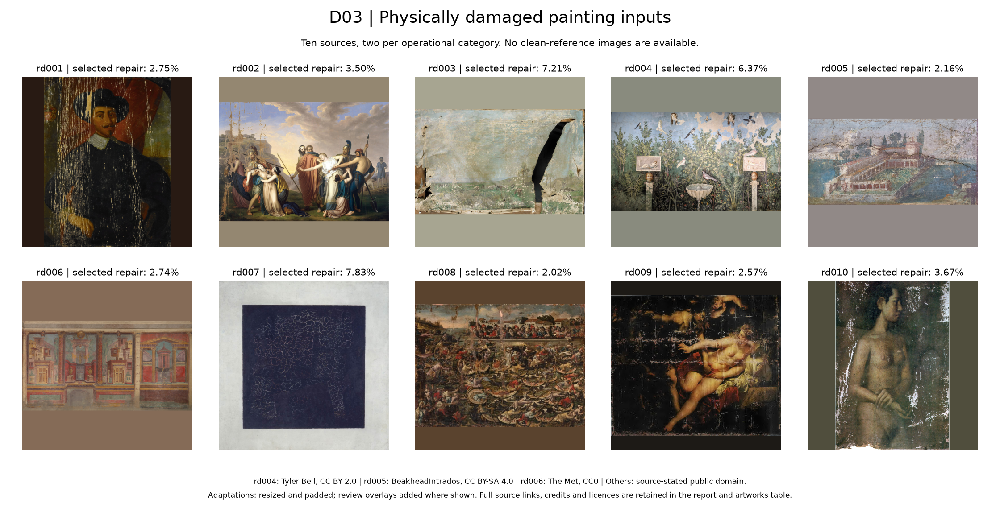

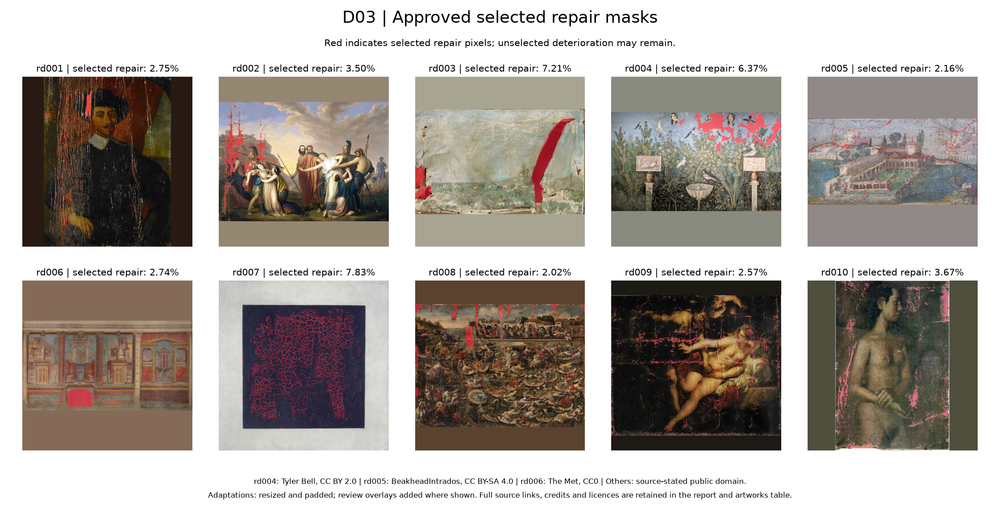

In [27]:
if not BATCH_7_READY:
    raise RuntimeError("Batch 7 validation is incomplete.")

display(
    NotebookImage(
        filename=str(PUBLICATION_RESULT["source_overview_path"]),
        width=1100,
    )
)

display(
    NotebookImage(
        filename=str(PUBLICATION_RESULT["mask_review_atlas_path"]),
        width=1100,
    )
)

## Batch 8 — Final completion gate and downstream handoff

The final gate verifies the canonical file set, artifact checksums, source
bindings, table populations, stable identifiers, researcher-approved masks,
inference-scale evidence and unchanged model configurations.

The saved validation from Batches 1–7 is retained. Completion adds the final
checks, updates the validation artifact record and finalizes the run manifest.
The scientific artifacts remain unchanged.

A completed D03 supplies ten cases and forty eligible case–model combinations
for D04 planning. Eligibility concerns the prepared inputs and masks; model
availability, runtime checks and restoration inference belong to D04.

The physical inputs have no known clean references. Their restoration results
must therefore remain separate from synthetic-case reference-fidelity scores.

In [28]:
BATCH_8_READY = False

if not globals().get("BATCH_7_READY", False):
    raise RuntimeError("The Batch 7 prerequisite is not satisfied.")

import importlib
from restoration_eval import real_damage_completion

real_damage_completion = importlib.reload(real_damage_completion)

COMPLETION_CONFIG_PATH = (
    PROJECT_ROOT / "config/datasets/real_damage_completion.yaml"
)

COMPLETION_CONFIG = real_damage_completion.load_completion_config(
    COMPLETION_CONFIG_PATH
)

HELPER_VERSIONS["real_damage_completion"] = (
    real_damage_completion.REAL_DAMAGE_COMPLETION_MODULE_VERSION
)

print("Completion configuration:", COMPLETION_CONFIG["config_version"])
print("Completion helper:", HELPER_VERSIONS["real_damage_completion"])
print("Dataset scope:", COMPLETION_CONFIG["dataset_scope"])
print("Cohort version:", COMPLETION_CONFIG["dataset_version"])

Completion configuration: 1.0.0
Completion helper: 1.0.0
Dataset scope: real_damage_10
Cohort version: 2.0.0


In [29]:
BATCH_8_READY = False

COMPLETION_RESULT = (
    real_damage_completion.complete_real_damage_dataset(
        PROJECT_ROOT,
        COMPLETION_CONFIG_PATH,
    )
)

VALIDATION = COMPLETION_RESULT["validation"]
RUN_MANIFEST = COMPLETION_RESULT["run_manifest"]
ARTIFACTS = COMPLETION_RESULT["artifacts"]
PUBLISHED_TABLES = COMPLETION_RESULT["tables"]
INVENTORY_RUN = COMPLETION_RESULT["inventory_run"]

print("Run ID:", RUN_MANIFEST["run_id"])
print("Run status:", RUN_MANIFEST["run_status"])
print("Completion gate passed:", RUN_MANIFEST["completion_gate_passed"])
print("Downstream ready:", RUN_MANIFEST["downstream_ready"])
print("Completed at UTC:", RUN_MANIFEST["completed_at_utc"])
print(
    "Active time:",
    round(COMPLETION_RESULT["elapsed_seconds"], 2),
    "seconds",
)
print("Combined validation:", VALIDATION.summary())

Run ID: run_d03_6a2e02fcf9a4b65a612b7cdf
Run status: completed
Completion gate passed: True
Downstream ready: True
Completed at UTC: 2026-11-15T01:07:42.388740Z
Active time: 5.4 seconds
Combined validation: {'check_count': 379, 'passed_count': 379, 'failed_count': 0, 'blocking_failure_count': 0, 'overall_passed': True, 'failed_check_ids': []}


In [30]:
BATCH_8_READY = False

BATCH_8_CHECKS = show_validation_stage(
    real_damage_completion.COMPLETION_STAGE
)

if not (
    RUN_MANIFEST["run_status"] == "completed"
    and RUN_MANIFEST["completion_gate_passed"]
    and RUN_MANIFEST["downstream_ready"]
):
    raise RuntimeError("The D03 completion manifest is not ready.")

BATCH_8_READY = True

VALIDATION_BY_BATCH = (
    VALIDATION.to_dataframe()
    .groupby("validation_stage", sort=True)
    .agg(
        checks=("check_id", "size"),
        passed=("passed", "sum"),
    )
    .reset_index()
)
VALIDATION_BY_BATCH["failed"] = (
    VALIDATION_BY_BATCH["checks"] - VALIDATION_BY_BATCH["passed"]
)

print("Validation by batch")
display(VALIDATION_BY_BATCH)

D04_HANDOFF = (
    PUBLISHED_TABLES["model_eligibility"]
    .groupby("model_id")
    .agg(
        cases=("case_id", "nunique"),
        eligible_pairs=("eligible", "sum"),
    )
    .reindex(CONFIG["downstream"]["primary_models"])
    .reset_index()
)

print("Prepared case–model handoff")
display(D04_HANDOFF)

print("Canonical files:", RUN_MANIFEST["observed_counts"]["canonical_files"])
print("Artifact records:", len(ARTIFACTS))
print("Known clean references:", RUN_MANIFEST["observed_counts"]["known_clean_references"])
print("Scientific data fingerprint:", RUN_MANIFEST["data_fingerprint"])
print("Restoration inference executed:", RUN_MANIFEST["completion_handoff"]["inference_executed"])
print("Model runtime and weights verified:", RUN_MANIFEST["completion_handoff"]["runtime_and_weights_verified"])
print(
    "Run manifest:",
    COMPLETION_RESULT["output_root"] / "manifests/run_manifest.json",
)

,stage,checks,passed,failed
0,batch_8_final_completion_gate,45,45,0


Validation by batch


,validation_stage,checks,passed,failed
0,batch_1_preflight,43,43,0
1,batch_2_source_validation,66,66,0
2,batch_3_preprocessing_smoke,35,35,0
3,batch_4_preprocessing_and_mask_candidates,63,63,0
4,batch_5_mask_review_and_inference_scale,43,43,0
5,batch_6_geometry_and_model_eligibility,49,49,0
6,batch_7_canonical_publication,35,35,0
7,batch_8_final_completion_gate,45,45,0


Prepared case–model handoff


,model_id,cases,eligible_pairs
0,opencv_telea,10,10
1,lama,10,10
2,hint_places2,10,10
3,stable_diffusion_inpainting,10,10


Canonical files: 34
Artifact records: 14
Known clean references: 0
Scientific data fingerprint: 6a2e02fcf9a4b65a612b7cdf5e9aa36846bc641ae8533f1f19635d5ebf00afe4
Restoration inference executed: False
Model runtime and weights verified: False
Run manifest: D:\Masters\FH\Thesis\painting-restoration-eval\outputs\d03_real_damage_dataset_preparation\manifests\run_manifest.json
